# CIC-IDS2017 Research Notebook
## Staged pipeline search, model tuning, and explainable feature analysis

**Study type:** empirical comparative study for binary network intrusion detection.

**Working objective:** systematically compare defensible, leakage-safe data-preparation and model configurations for Logistic Regression, Random Forest, and XGBoost; tune only promising complete pipelines; explain a selected tree model with SHAP; and test whether SHAP-guided feature reduction preserves detection performance.

**Important scope statement:** this notebook seeks the strongest *defensible configuration under the stated dataset, split protocol, metric, search budget, and hardware constraints*. It does not claim to discover a universally best preprocessing method or a universally best NIDS model.

### Research questions
- **RQ1:** How do selected preprocessing and model configurations affect binary intrusion-detection performance on CIC-IDS2017?
- **RQ2:** How do class weighting and training-only resampling affect the Benign/Attack trade-off?
- **RQ3:** Which flow features contribute most to the selected tree model's predictions?
- **RQ4:** Can a smaller SHAP-ranked feature subset preserve useful detection performance?

### Research boundary
This is an offline experimental paper. Deployment, real-time serving, CI/CD, production monitoring, and model governance are not experimental variables. UV, Git/GitHub, and DVC are used for reproducibility, not to claim a new MLOps contribution.

## 1. Complete experimental workflow

```mermaid
flowchart TD
 A["Eight original CIC-IDS2017 CSV files"] --> B["Ingestion, schema and provenance audit"]
 B --> C["EDA and data-quality audit"]
 C --> D["Deterministic corrections + documented data decisions"]
 D --> E["Choose split from generalization question"]
 E --> F["Train / validation / untouched test"]
 F --> G["Training-only cross-validation"]
 G --> H["Level 0: default baseline pipelines"]
 H --> I["Level 1: one-family-at-a-time pipeline GridSearchCV"]
 I --> J["Level 2: combine promising factors; validate finalists"]
 J --> K["Level 3: model hyperparameter GridSearchCV"]
 K --> L["Validation selection"]
 L --> M["Refit selected pipeline on train + validation"]
 M --> N["Final test evaluation once"]
 L --> O["SHAP from training data"]
 O --> P["Top-k feature subsets; validate on validation set"]
 P --> Q["Refit reduced feature pipeline on train + validation"]
 Q --> N
 N --> R["Metrics, error analysis, cost and limitations"]
```

### The two searches are different
1. **Pipeline-level search:** compare candidate choices for imputation, outlier treatment, categorical handling, scaling where model-relevant, feature selection, and imbalance handling. Change one meaningful family at a time while keeping the rest fixed.
2. **Model-level search:** after choosing a promising complete pipeline, tune that model's hyperparameters using a compact `GridSearchCV` space.

The experimental unit is the **complete pipeline**, not just the estimator. We do not brute-force every possible Cartesian product. We establish a baseline, run controlled factor searches, combine a small number of defensible candidates, tune finalists, and reserve the test set for final reporting.

## 2. What from the supplied 36-page ML-pipeline framework applies to this paper?

The uploaded document is a useful catalogue of the end-to-end ML lifecycle. Its main pillars—problem framing, data collection, EDA, cleaning, feature engineering, split/CV design, model selection/training, tuning, evaluation, and explainability—directly inform this study. Deployment, live monitoring, CI/CD, and production governance are valid ML lifecycle topics, but they are outside this offline research experiment. See the supplied document's end-to-end pillars and minimal order. (supplied PDF, pp. 1–2 and 9).

| PDF pillar | How it is handled in this CIC-IDS2017 study |
|---|---|
| Problem framing | Binary flow classification: `BENIGN=0`, every other non-empty attack label = `1`. Keep original attack-family labels for descriptive analysis. |
| Data collection / ingestion | Inventory eight CSVs, verify schema consistency, record source file and dataset version. |
| EDA | Shapes, class distributions, feature types, missingness, infinities, duplicates, correlations, skew and range summaries. |
| Cleaning / preprocessing | Numeric imputation, Protocol handling, train-fitted clipping/transformations and model-specific scaling. |
| Feature engineering / selection | Start with documented CICFlowMeter features; test selected filter methods; use SHAP after fitting for a separate reduction experiment. |
| Splitting / CV | Main split is stratified random unless the research question calls for a group or chronological evaluation. CV must match the chosen split logic. |
| Imbalance | Compare natural distribution, model-specific class weights, random oversampling and random undersampling. |
| Model selection / training | Logistic Regression, Random Forest and XGBoost; default baselines first. |
| Hyperparameter tuning | Compact `GridSearchCV` for discrete shortlisted settings. Use Randomized/Bayesian search only if a wider search later becomes justified. |
| Evaluation | Attack precision/recall/F1, Macro-F1, balanced accuracy, PR-AUC, ROC-AUC, FPR/FNR, MCC and confusion matrices. |
| Explainability | SHAP global/local analysis and validation of reduced feature sets. |
| Deployment / monitoring / governance | Not part of this paper; keep as future engineering work. |

### Non-negotiable methodology rules from the framework
- Split before fitting learned transformations; imputation, scaling, encoding categories, outlier caps, feature selection and resampling belong inside the CV training fold. (supplied PDF, pp. 11–12).
- Choose random, stratified, group or time splitting based on the data structure and intended generalization question—not whichever split produces the highest score. (supplied PDF, pp. 19–20).
- Compare a small number of complete pipeline candidates, then tune model hyperparameters. Avoid an enormous exhaustive search. (supplied PDF, pp. 27–29).
- Treat the test set as untouched until final reporting. Do not use it to pick preprocessing, features, thresholds, or hyperparameters.

## 2A. Full method catalogue: available methods versus methods suitable for this dataset

This section preserves the method families covered by the supplied PDF but distinguishes **(a) methods that are actually searched in this study, (b) methods retained as optional follow-up experiments, and (c) methods that do not fit the data/task**. A method being listed does not mean it should automatically be applied.

| Family | Methods in the general ML toolkit | CIC-IDS2017 decision | Search / implementation status |
|---|---|---|---|
| Missing values | Drop rows, drop columns, mean, median, mode, constant, KNN, iterative/model-based imputation, missingness indicators | Audit first. For numeric flow features, compare median, mean, constant-zero, and indicator variants. For Protocol, use most-frequent or `Missing` only if values are missing. | Median/mean/constant and indicator are searched. KNN/Iterative are deferred: expensive at this row count and only justified if missingness is substantial and simple methods are inadequate. Drop-row/column is decided by data-quality evidence, not a blind grid. |
| Outliers | Domain correction, removal, capping/winsorizing, log/square-root/Box-Cox/Yeo-Johnson, robust scaling, binning, Isolation Forest/LOF | Network-flow extremes can be genuine attacks. Correct impossible values only with defensible domain rules; do not delete rare rows just because they are extreme. | No treatment versus train-fitted quantile clipping is searched. Yeo-Johnson is a separate distribution-transform candidate for Logistic Regression. Isolation Forest/LOF are not used as generic outlier cleaners. |
| Duplicates | Exact-row, key/entity duplicates, near duplicates, feature duplicates, conflicting-label duplicates | Audit exact rows, identical feature vectors, and feature vectors associated with conflicting labels. Duplicate groups can be kept together in a group split. | Audit always; removal is off by default. Duplicate-grouped split is a separate evaluation protocol, not a tuning option. |
| Data types | Numeric strings, dates, booleans, categories stored as integers, IDs stored as numeric, mixed missing markers | Convert flow statistics to numeric; treat `Protocol` as nominal categorical; exclude Flow ID/IP/Timestamp from predictors but retain timestamp for time splitting/auditing. | Implemented in data preparation. |
| Categorical encoding | One-hot, ordinal, label, target, frequency, hashing, binary, embeddings/native category handling | Protocol has low cardinality and no natural order. One-hot is appropriate; dropping Protocol is a feature ablation. Ordinal/label encoding would invent order; target/frequency/hash/embeddings solve high-cardinality cases we do not have here. | One-hot versus drop-ablation searched. Other encoders documented but not searched because they are not justified for Protocol. (supplied PDF, pp. 15–16). |
| Numeric scaling | None, standard/Z-score, min-max, robust, max-abs | Logistic Regression is scale-sensitive; tree models are generally not. Robust scaling is not the same as removing outliers. | For Logistic Regression: none, StandardScaler, RobustScaler, MinMaxScaler. Tree models: no scaling by default. (supplied PDF, pp. 16–17). |
| Numeric transformations | `log1p`, square root, Box-Cox, Yeo-Johnson, quantile transform | Choose only after inspecting skew/range. Box-Cox/log require positive data; Yeo-Johnson can handle negative values. | Yeo-Johnson candidate for Logistic Regression. `log1p` may be added for specifically non-negative, heavily skewed columns after EDA; not applied blindly to every column. |
| Feature engineering | Domain ratios, flow rates, interaction/polynomial features, aggregations, time/lag/rolling features, embeddings | CICFlowMeter already contains many flow-level rates/statistics. Avoid duplicating them without a domain rationale. Do not use timestamp as a predictive shortcut in the primary model. | Existing features first. Optional, separately justified ratio/interaction ablation only if feature definitions are understood. No blind polynomial expansion. |
| Feature selection | Variance threshold, correlation filter, ANOVA/chi-square/mutual information, L1/Lasso, RFE/wrapper, tree embedded importance, permutation importance, SHAP | Start with no selection; test variance filtering and a small set of univariate filters inside CV. SHAP selection is a separate post-fit experiment. | Passthrough, VarianceThreshold, ANOVA SelectKBest and optional mutual-information SelectKBest. RFE/L1/embedded/permutation are documented follow-ups, not in the default search. SHAP top-k runs after model selection. (supplied PDF, pp. 18–19). |
| Dimensionality reduction | PCA, Truncated SVD, LDA, t-SNE, UMAP, autoencoders, feature hashing | PCA may be useful for compression but makes original-feature interpretation harder. t-SNE/UMAP are primarily visualization; hashing/autoencoders are unnecessary for this first tabular study. | Not in primary classifier search. May be a separately labelled exploratory visualization/compression study. (supplied PDF, pp. 19). |
| Splitting | Random, stratified, time-based, group-based, holdout | Main stratified random split estimates row-level IID performance. Duplicate-grouped and chronological splits are separate robustness/generalization experiments. | User chooses split before modelling. Never select split strategy by highest score. |
| Cross-validation | K-fold, StratifiedKFold, GroupKFold/StratifiedGroupKFold, TimeSeriesSplit, repeated CV | Use stratified folds for the main imbalanced classification benchmark; group/time CV only when corresponding holdout protocol is used. | CV strategy follows `SPLIT_STRATEGY`. Test set remains untouched. |
| Imbalance | No action, class weights, sample weights, random over/undersampling, SMOTE/SMOTENC, ADASYN, Tomek links, threshold tuning, cost-sensitive learning, anomaly detection | Start with natural distribution and class weights. Random samplers are comparison candidates. Ordinary SMOTE after one-hot encoding can generate fractional Protocol indicators; use a dedicated categorical-aware SMOTENC design if later justified. | None, model-appropriate class weighting, RandomOverSampler and RandomUnderSampler searched. SMOTE/ADASYN/Tomek/anomaly detection/threshold optimization deferred. (supplied PDF, pp. 21–22). |
| Model families | Linear/logistic, trees/ensembles, SVM, KNN, Naive Bayes, clustering, neural nets, Transformers, bagging/boosting/stacking | This paper is supervised binary classification. Clustering is not a direct replacement for the supervised task; deep learning and additional models would expand scope. | Logistic Regression, Random Forest and XGBoost are the selected comparison models. SVM/KNN/NB/NN are possible future baselines, not default candidates. |
| Hyperparameter search | Default, small grid, GridSearchCV, RandomizedSearchCV, Bayesian/TPE/SMAC, successive halving, AutoML | Use a small explicit grid for a few finalists. If the grid becomes wide or continuous, RandomizedSearchCV or Bayesian optimization is more efficient. | GridSearchCV is used for compact pipeline and model searches. Search results, fold means/std and runtime are exported. (supplied PDF, pp. 27–29). |
| Evaluation | Accuracy, precision, recall, F1, ROC/PR-AUC, confusion matrix, calibration, thresholds, error/slice analysis, robustness, confidence intervals | Attack false negatives and benign false alarms both matter. Accuracy alone is insufficient under imbalance. | Report per-class and aggregate metrics, confusion matrices, ROC/PR curves, CV mean/std, fit time and inference latency. |
| Explainability | SHAP, LIME, permutation importance, PDP, counterfactuals, surrogate models, model cards/fairness | SHAP can explain model-dependent feature contributions and help investigate shortcuts; it does not establish causality. | SHAP global/local analysis for the selected tree model; optional permutation importance for comparison. LIME/counterfactuals not required for this paper. |
| Production lifecycle | Serialization, Docker, REST/gRPC, batch/stream/edge/cloud deployment, A/B/canary/shadow, monitoring, drift, retraining, CI/CD, registries, governance | Valid lifecycle topics but not necessary to answer the offline experimental research questions. | Out of scope; retain for future work, not this notebook's search space. |

### Model-dependency rules
- Scaling is tested for Logistic Regression; it is not a useful generic search axis for Random Forest/XGBoost.
- Protocol is nominal, so one-hot encoding is the defensible primary representation; target encoding is unnecessary and brings fold-leakage risk.
- Samplers are inside an imbalanced-learn pipeline so they run only during each training fold.
- Feature selectors are inside the CV pipeline so the selector is refit within each training fold.
- Split choice is a design decision, not a score-optimization parameter.
- If the model family, metric, or data structure changes, the search space must be reconsidered.

The supplied framework explicitly identifies these dependencies and warns against comparing pipelines that change many factors at once. (supplied PDF, pp. 22–23 and 29–30).

## 2B. Search strategy and experiment ledger

The notebook stores the candidate method lists explicitly. The lists are not all multiplied into one enormous grid. Each eligible family is searched separately, then the best 2–4 defensible pipeline candidates are combined and validated. This is the staged factorial design recommended in the supplied framework. <FileCite ref_id="turn3file0" line_range_start={1345} line_range_end={1359} /> <FileCite ref_id="turn3file0" line_range_start={1510} line_range_end={1660} />

In [1]:
METHOD_CATALOG = [
    {"family": "numeric_imputation", "method": "median", "status": "SEARCHED", "reason": "Robust baseline for skewed flow statistics."},
    {"family": "numeric_imputation", "method": "mean", "status": "SEARCHED", "reason": "Comparison baseline for less-skewed features."},
    {"family": "numeric_imputation", "method": "constant_zero", "status": "SEARCHED", "reason": "Simple sentinel baseline; interpret cautiously."},
    {"family": "numeric_imputation", "method": "KNN", "status": "DEFERRED", "reason": "Potentially expensive at CIC-IDS2017 scale."},
    {"family": "numeric_imputation", "method": "Iterative", "status": "DEFERRED", "reason": "More computationally expensive; only if simple methods are inadequate."},
    {"family": "numeric_imputation", "method": "missing_indicator", "status": "SEARCHED", "reason": "Tests whether missingness itself carries signal."},
    {"family": "categorical_imputation", "method": "most_frequent", "status": "CONDITIONAL", "reason": "Only if Protocol values are missing."},
    {"family": "categorical_imputation", "method": "constant_Missing", "status": "CONDITIONAL", "reason": "Only if Protocol values are missing."},
    {"family": "outlier_treatment", "method": "none", "status": "SEARCHED", "reason": "Preserve rare but potentially genuine attack flows."},
    {"family": "outlier_treatment", "method": "quantile_clip_1_99", "status": "SEARCHED", "reason": "Train-fitted clipping candidate."},
    {"family": "outlier_treatment", "method": "row_removal", "status": "NOT_DEFAULT", "reason": "Could delete rare attack events; only remove proven corrupt records."},
    {"family": "numeric_transform", "method": "Yeo-Johnson", "status": "SEARCHED_FOR_LR", "reason": "Handles negative and non-negative skewed values."},
    {"family": "numeric_transform", "method": "log1p", "status": "CONDITIONAL", "reason": "Only for individually verified non-negative, skewed variables."},
    {"family": "encoding", "method": "OneHotEncoder", "status": "SEARCHED", "reason": "Suitable for low-cardinality nominal Protocol."},
    {"family": "encoding", "method": "drop_Protocol", "status": "ABLATION", "reason": "Measures whether Protocol contributes predictive signal."},
    {"family": "encoding", "method": "ordinal_or_label", "status": "NOT_APPLICABLE", "reason": "Would create artificial order between protocol codes."},
    {"family": "encoding", "method": "target_frequency_hash_embedding", "status": "NOT_APPLICABLE", "reason": "Designed for high-cardinality categories; Protocol is low-cardinality."},
    {"family": "scaling", "method": "none", "status": "SEARCHED", "reason": "Tree model default; also a Logistic Regression candidate."},
    {"family": "scaling", "method": "standard", "status": "SEARCHED_FOR_LR", "reason": "Mean-zero/unit-variance scaling for Logistic Regression."},
    {"family": "scaling", "method": "robust", "status": "SEARCHED_FOR_LR", "reason": "Median/IQR scaling when features contain extreme values."},
    {"family": "scaling", "method": "minmax", "status": "SEARCHED_FOR_LR", "reason": "Bounded range candidate; sensitive to extreme values."},
    {"family": "feature_selection", "method": "none", "status": "SEARCHED", "reason": "Baseline with all eligible features."},
    {"family": "feature_selection", "method": "VarianceThreshold", "status": "SEARCHED", "reason": "Fold-local removal of zero-variance features."},
    {"family": "feature_selection", "method": "ANOVA_SelectKBest", "status": "SEARCHED", "reason": "Fast supervised filter for classification."},
    {"family": "feature_selection", "method": "MutualInformation_SelectKBest", "status": "OPTIONAL_SEARCH", "reason": "Nonlinear univariate dependence; enable after pilot."},
    {"family": "feature_selection", "method": "RFE_L1_tree_embedded_permutation", "status": "DEFERRED", "reason": "Additional compute and methodological complexity."},
    {"family": "feature_selection", "method": "SHAP_top_k", "status": "POST_FIT_EXPERIMENT", "reason": "Separate explainability-guided feature reduction."},
    {"family": "dimensionality_reduction", "method": "PCA", "status": "DEFERRED", "reason": "May reduce original-feature interpretability."},
    {"family": "dimensionality_reduction", "method": "tSNE_UMAP", "status": "VISUALIZATION_ONLY", "reason": "Not primary predictive features in this study."},
    {"family": "split", "method": "stratified_random", "status": "PRIMARY_DEFAULT", "reason": "Row-level IID benchmark; interpret duplicate-overlap audit."},
    {"family": "split", "method": "duplicate_grouped", "status": "ROBUSTNESS_OPTION", "reason": "Keep identical feature vectors in one partition."},
    {"family": "split", "method": "chronological", "status": "ROBUSTNESS_OPTION", "reason": "Later-time evaluation; attack-day scenario shift must be acknowledged."},
    {"family": "cross_validation", "method": "StratifiedKFold", "status": "PRIMARY_DEFAULT", "reason": "Maintains class proportions in row-level CV."},
    {"family": "cross_validation", "method": "StratifiedGroupKFold", "status": "CONDITIONAL", "reason": "Use with duplicate-grouped split."},
    {"family": "cross_validation", "method": "TimeSeriesSplit", "status": "CONDITIONAL", "reason": "Use with chronological split; some folds may lack one class."},
    {"family": "imbalance", "method": "none", "status": "SEARCHED", "reason": "Natural-prevalence baseline."},
    {"family": "imbalance", "method": "class_weight_or_scale_pos_weight", "status": "SEARCHED", "reason": "Cost-sensitive learning without synthetic rows."},
    {"family": "imbalance", "method": "RandomOverSampler", "status": "SEARCHED", "reason": "Duplicates minority training rows inside each fold."},
    {"family": "imbalance", "method": "RandomUnderSampler", "status": "SEARCHED", "reason": "Reduces majority training rows inside each fold."},
    {"family": "imbalance", "method": "SMOTE_SMOTENC_ADASYN_Tomek", "status": "DEFERRED", "reason": "Needs a categorical-aware, fold-local design and separate compute budget."},
    {"family": "model", "method": "LogisticRegression", "status": "SEARCHED", "reason": "Linear baseline."},
    {"family": "model", "method": "RandomForest", "status": "SEARCHED", "reason": "Bagging tree ensemble."},
    {"family": "model", "method": "XGBoost", "status": "SEARCHED_IF_INSTALLED", "reason": "Gradient-boosted tree ensemble."},
    {"family": "model", "method": "SVM_KNN_NaiveBayes_NN", "status": "FUTURE_WORK", "reason": "Would broaden model scope beyond the present paper."},
    {"family": "hyperparameter_search", "method": "GridSearchCV", "status": "SEARCHED", "reason": "Compact explicit discrete grids for shortlisted candidates."},
    {"family": "hyperparameter_search", "method": "Randomized_Bayesian_Halving_AutoML", "status": "FUTURE_OPTION", "reason": "More appropriate than a huge exhaustive grid if search spaces expand."},
]



## 3. UV environment

Run in PowerShell from the project root, not in a notebook `%pip` cell:

```powershell
uv add numpy pandas scipy scikit-learn matplotlib seaborn xgboost shap pyarrow psutil imbalanced-learn
uv add --dev jupyterlab ipykernel
uv sync
uv run python -m ipykernel install --user --name cicids2017 --display-name "Python (CIC-IDS2017 - UV)"
uv run jupyter lab
```

Select **Python (CIC-IDS2017 - UV)** as the notebook kernel. `GridSearchCV` is provided by scikit-learn; `ImbPipeline` and the samplers are provided by imbalanced-learn. We are not adding MLflow, Docker, CI/CD or pipeline orchestration to this experimental notebook.

## 4. Imports and environment verification

In [2]:
from __future__ import annotations

import json, math, os, platform, time, warnings
from collections import Counter
from dataclasses import dataclass
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, PowerTransformer
)
from sklearn.feature_selection import (
    SelectKBest, VarianceThreshold, f_classif, mutual_info_classif
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, StratifiedGroupKFold, TimeSeriesSplit,
    GridSearchCV, RandomizedSearchCV, cross_validate
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
    roc_auc_score, average_precision_score, matthews_corrcoef, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

try:
    import xgboost as xgb
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except Exception as exc:
    XGBOOST_AVAILABLE = False
    print("XGBoost unavailable:", repr(exc))

try:
    import shap
    SHAP_AVAILABLE = True
except Exception as exc:
    SHAP_AVAILABLE = False
    print("SHAP unavailable:", repr(exc))

try:
    import psutil
except Exception:
    psutil = None

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", XGBOOST_AVAILABLE, "| SHAP:", SHAP_AVAILABLE)

Python: 3.11.16
pandas: 3.1.1
NumPy: 2.4.6
scikit-learn: 1.9.1
XGBoost: True | SHAP: True


e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 5. Project paths and experiment settings

In [ ]:
def find_project_root(start=None):
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Start Jupyter inside the project or set PROJECT_DIR manually.")

PROJECT_DIR = find_project_root()
RAW_DIR = PROJECT_DIR / "data" / "raw"
AUDIT_DIR = PROJECT_DIR / "data" / "processed" / "audit"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
TABLES_DIR = PROJECT_DIR / "reports" / "tables"

for folder in [AUDIT_DIR, FIGURES_DIR, TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
CHUNK_SIZE = 100_000
MAX_ROWS_FOR_MODELING = 300_000    # Streaming, label-stratified modeling sample; None loads all 2.83M rows (too large for current RAM)
SEARCH_MAX_ROWS = 25_000           # Separate training-only CV subset; does NOT cap the initial data load
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15
CV_FOLDS = 3
SEARCH_N_JOBS = 1                  # avoid nested CPU oversubscription during GridSearchCV
MODEL_N_JOBS = -1
PRIMARY_SCORING = "f1_macro"

# AUC scorers can be undefined for a time-based fold containing only one class.
SCORING = {
    "f1_macro": "f1_macro",
    "f1_attack": "f1",
    "precision_attack": "precision",
    "recall_attack": "recall",
    "balanced_accuracy": "balanced_accuracy",
}

# Add threshold-independent ranking metrics for stratified/grouped folds.
# For chronological CV, these can be undefined when a fold has one class.
SPLIT_STRATEGY = "stratified_random"  # stratified_random | duplicate_grouped | chronological
CV_STRATEGY = {
    "stratified_random": "stratified",
    "duplicate_grouped": "duplicate_grouped",
    "chronological": "chronological",
}[SPLIT_STRATEGY]
if CV_STRATEGY != "chronological":
    SCORING.update({"roc_auc": "roc_auc", "average_precision": "average_precision"})

REMOVE_EXACT_DUPLICATES = False   # default: audit but retain; compare removal only as a separate study
SHAP_SAMPLE_SIZE = 750
TOP_K_FEATURES = [10, 20, 30]
INCLUDE_MUTUAL_INFO_IN_SEARCH = True

# Search budget. The CV subset is only for choosing configurations; final refits use train+validation.
BASE_RF_ESTIMATORS = 100
BASE_XGB_ESTIMATORS = 60
XGB_SEARCH_N_ESTIMATORS = [80, 150]
RF_SEARCH_N_ESTIMATORS = [100, 200]

IDENTIFIER_COLUMNS = {
    "flow id", "source ip", "destination ip", "timestamp", "source_file", "row_id"
}
LABEL_NAMES = {"label", "label_original", "label_normalized", "target"}

print("Project:", PROJECT_DIR)
print("Raw:", RAW_DIR)
print("Split:", SPLIT_STRATEGY, "| CV:", CV_STRATEGY)
print("Modeling sample cap:", MAX_ROWS_FOR_MODELING, "| CV search subset cap:", SEARCH_MAX_ROWS)
print("CV folds:", CV_FOLDS)

Project: E:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection
Raw: E:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\data\raw
Split: stratified_random | CV: stratified
Modeling sample cap: 300000 | CV search subset cap: 25000
CV folds: 3


## 6. Reusable result and shape helpers

In [4]:
def save_table(frame, filename):
    path = TABLES_DIR / filename
    frame.to_csv(path, index=False)
    return path

def record_shape(stage, frame, target=None):
    row = {
        "stage": stage,
        "rows": int(frame.shape[0]),
        "columns": int(frame.shape[1]),
        "memory_mb": float(frame.memory_usage(deep=True).sum() / 1024**2),
    }
    if target is not None:
        counts = target.value_counts().to_dict()
        row["benign"] = int(counts.get(0, 0))
        row["attack"] = int(counts.get(1, 0))
    return row

def calculate_metrics(y_true, y_pred, y_probability):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_probability = np.asarray(y_probability)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    binary_available = np.unique(y_true).size == 2
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_attack": precision_score(y_true, y_pred, zero_division=0),
        "recall_attack": recall_score(y_true, y_pred, zero_division=0),
        "f1_attack": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_probability) if binary_available else np.nan,
        "average_precision": average_precision_score(y_true, y_probability) if binary_available else np.nan,
        "mcc": matthews_corrcoef(y_true, y_pred),
        "false_positive_rate": fp / (fp + tn) if (fp + tn) else np.nan,
        "false_negative_rate": fn / (fn + tp) if (fn + tp) else np.nan,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

def rank_validation_results(frame):
    # Primary rank: Macro-F1. Tie-breakers: Attack Recall, then lower FPR.
    return frame.sort_values(
        ["f1_macro", "recall_attack", "false_positive_rate"],
        ascending=[False, False, True], na_position="last"
    ).reset_index(drop=True)

def stratified_search_subset(X, y, max_rows, seed=RANDOM_STATE):
    if max_rows is None or len(X) <= max_rows:
        return X.copy(), y.copy()
    if max_rows < 4:
        raise ValueError("SEARCH_MAX_ROWS is too small.")
    X_sub, _, y_sub, _ = train_test_split(
        X, y, train_size=max_rows, random_state=seed, stratify=y
    )
    return X_sub.copy(), y_sub.copy()

In [5]:
method_catalog_df = pd.DataFrame(METHOD_CATALOG)
display(method_catalog_df)
save_table(method_catalog_df, "method_catalog_and_search_disposition.csv")

,family,method,status,reason
0,numeric_imputation,median,SEARCHED,Robust baseline for skewed flow statistics.
1,numeric_imputation,mean,SEARCHED,Comparison baseline for less-skewed features.
2,numeric_imputation,constant_zero,SEARCHED,Simple sentinel baseline; interpret cautiously.
3,numeric_imputation,KNN,DEFERRED,Potentially expensive at CIC-IDS2017 scale.
4,numeric_imputation,Iterative,DEFERRED,More computationally expensive; only if simple...
5,numeric_imputation,missing_indicator,SEARCHED,Tests whether missingness itself carries signal.
6,categorical_imputation,most_frequent,CONDITIONAL,Only if Protocol values are missing.
7,categorical_imputation,constant_Missing,CONDITIONAL,Only if Protocol values are missing.
8,outlier_treatment,none,SEARCHED,Preserve rare but potentially genuine attack f...
9,outlier_treatment,quantile_clip_1_99,SEARCHED,Train-fitted clipping candidate.


WindowsPath('E:/03 Education/Zagazig Material/Masters/First Year First Term/Machine Learning/Research Paper/ML for Intrusion Detection/reports/tables/method_catalog_and_search_disposition.csv')

## 7. Raw file inventory and schema validation

The ZIP is inspected by filename only; the notebook will not extract it automatically. The eight extracted CSV files are the modeling input.

In [6]:
if not RAW_DIR.exists():
    raise FileNotFoundError(f"Raw-data folder not found: {RAW_DIR}")
csv_files = sorted(RAW_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found under {RAW_DIR}")

inventory_df = pd.DataFrame([
    {"file": p.name, "size_mb": round(p.stat().st_size / 1024**2, 2),
     "size_bytes": p.stat().st_size}
    for p in csv_files
])
display(inventory_df)
print("CSV count:", len(csv_files), "| ZIP files:", [p.name for p in RAW_DIR.glob("*.zip")])
save_table(inventory_df, "raw_file_inventory.csv")

def read_csv_header(path):
    last_error = None
    for encoding in ["utf-8-sig", "cp1252", "latin1"]:
        try:
            header = pd.read_csv(path, nrows=0, encoding=encoding)
            columns = [str(c).strip() for c in header.columns]
            if len(columns) != len(set(columns)):
                raise ValueError(f"Duplicate headers after strip: {path.name}")
            return columns, encoding
        except Exception as exc:
            last_error = exc
    raise RuntimeError(f"Could not read {path.name}: {last_error}")

header_info = {}
for path in csv_files:
    columns, encoding = read_csv_header(path)
    header_info[path.name] = {"columns": columns, "encoding": encoding}

reference_columns = header_info[csv_files[0].name]["columns"]
schema_rows = []
for path in csv_files:
    cols = header_info[path.name]["columns"]
    schema_rows.append({
        "file": path.name,
        "encoding": header_info[path.name]["encoding"],
        "n_columns": len(cols),
        "matches_reference": cols == reference_columns,
        "missing_columns": sorted(set(reference_columns) - set(cols)),
        "extra_columns": sorted(set(cols) - set(reference_columns)),
    })

schema_audit_df = pd.DataFrame(schema_rows)
display(schema_audit_df)
save_table(schema_audit_df, "schema_audit.csv")
if not schema_audit_df["matches_reference"].all():
    raise ValueError("CSV schemas differ; resolve before concatenating.")

label_matches = [c for c in reference_columns if c.strip().lower() == "label"]
if len(label_matches) != 1:
    raise ValueError(f"Expected one Label column, found: {label_matches}")
LABEL_COLUMN = label_matches[0]

,file,size_mb,size_bytes
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,73.55,77123859
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,73.34,76906168
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,55.62,58316725
3,Monday-WorkingHours.pcap_ISCX.csv,168.73,176927918
4,Thursday-WorkingHours-Afternoon-Infilteration....,79.25,83102436
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,49.61,52023263
6,Tuesday-WorkingHours.pcap_ISCX.csv,128.82,135078995
7,Wednesday-workingHours.pcap_ISCX.csv,214.74,225166395


CSV count: 8 | ZIP files: ['archive.zip']


,file,encoding,n_columns,matches_reference,missing_columns,extra_columns
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,utf-8-sig,79,True,[],[]
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,utf-8-sig,79,True,[],[]
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,utf-8-sig,79,True,[],[]
3,Monday-WorkingHours.pcap_ISCX.csv,utf-8-sig,79,True,[],[]
4,Thursday-WorkingHours-Afternoon-Infilteration....,utf-8-sig,79,True,[],[]
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,utf-8-sig,79,True,[],[]
6,Tuesday-WorkingHours.pcap_ISCX.csv,utf-8-sig,79,True,[],[]
7,Wednesday-workingHours.pcap_ISCX.csv,utf-8-sig,79,True,[],[]


## 8. Full-dataset label audit using chunks

In [7]:
def audit_labels_in_file(path, encoding, chunksize=CHUNK_SIZE):
    """Count raw labels in chunks while reading only the Label column.

    LABEL_COLUMN is normalized during header inspection, but pandas usecols
    matches the original CSV header spelling. The callable below handles
    headers such as " Label" and "Label ".
    """
    counts = Counter()
    total_rows = 0

    def is_label_column(raw_name):
        normalized = str(raw_name).replace("\ufeff", "").strip().casefold()
        return normalized == "label"

    for chunk in pd.read_csv(
        path,
        usecols=is_label_column,
        chunksize=chunksize,
        encoding=encoding,
        low_memory=False,
    ):
        if chunk.shape[1] != 1:
            raise ValueError(
                f"Expected exactly one Label column in {path.name}; "
                f"read {chunk.shape[1]} columns: {chunk.columns.tolist()}"
            )

        # usecols keeps the raw spelling; iloc avoids relying on its exact name.
        labels = chunk.iloc[:, 0].astype("string").str.strip()
        labels = labels.mask(labels.eq(""), pd.NA)

        for label, count in labels.value_counts(dropna=False).items():
            key = "<MISSING>" if pd.isna(label) else str(label)
            counts[key] += int(count)

        total_rows += len(chunk)

    return total_rows, counts

audit_rows = []
for path in csv_files:
    n_rows, counts = audit_labels_in_file(path, header_info[path.name]["encoding"])
    print(f"\\n{path.name}: {n_rows:,} rows")
    for label, count in counts.most_common():
        print(f"  {label}: {count:,}")
        audit_rows.append({"file": path.name, "label": label, "count": count, "file_rows": n_rows})

label_audit_df = pd.DataFrame(audit_rows)
display(label_audit_df)
save_table(label_audit_df, "label_distribution_by_file.csv")
full_label_counts = label_audit_df.groupby("label")["count"].sum().sort_values(ascending=False)
print("Total rows in all CSVs:", int(label_audit_df.drop_duplicates("file")["file_rows"].sum()))
display(full_label_counts.to_frame("count"))

\nFriday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 225,745 rows
  DDoS: 128,027
  BENIGN: 97,718
\nFriday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 286,467 rows
  PortScan: 158,930
  BENIGN: 127,537
\nFriday-WorkingHours-Morning.pcap_ISCX.csv: 191,033 rows
  BENIGN: 189,067
  Bot: 1,966
\nMonday-WorkingHours.pcap_ISCX.csv: 529,918 rows
  BENIGN: 529,918
\nThursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: 288,602 rows
  BENIGN: 288,566
  Infiltration: 36
\nThursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: 170,366 rows
  BENIGN: 168,186
  Web Attack � Brute Force: 1,507
  Web Attack � XSS: 652
  Web Attack � Sql Injection: 21
\nTuesday-WorkingHours.pcap_ISCX.csv: 445,909 rows
  BENIGN: 432,074
  FTP-Patator: 7,938
  SSH-Patator: 5,897
\nWednesday-workingHours.pcap_ISCX.csv: 692,703 rows
  BENIGN: 440,031
  DoS Hulk: 231,073
  DoS GoldenEye: 10,293
  DoS slowloris: 5,796
  DoS Slowhttptest: 5,499
  Heartbleed: 11


,file,label,count,file_rows
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,DDoS,128027,225745
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,BENIGN,97718,225745
2,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,PortScan,158930,286467
3,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,BENIGN,127537,286467
4,Friday-WorkingHours-Morning.pcap_ISCX.csv,BENIGN,189067,191033
5,Friday-WorkingHours-Morning.pcap_ISCX.csv,Bot,1966,191033
6,Monday-WorkingHours.pcap_ISCX.csv,BENIGN,529918,529918
7,Thursday-WorkingHours-Afternoon-Infilteration....,BENIGN,288566,288602
8,Thursday-WorkingHours-Afternoon-Infilteration....,Infiltration,36,288602
9,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,BENIGN,168186,170366


Total rows in all CSVs: 2830743


,count
label,
BENIGN,2273097
DoS Hulk,231073
PortScan,158930
DDoS,128027
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499


## 9. Load data: full mode or reproducible stratified streaming sample

**Important distinction:** `MAX_ROWS_FOR_MODELING` controls how many rows are loaded from the eight source CSVs. `SEARCH_MAX_ROWS` is applied later, after the train/validation/test split, and limits only the training subset used for cross-validation searches. It does not limit the initial load or validation/final-fit rows. With the reported 2.6 GB available RAM, the default modeling sample is set to 200,000 rows. The full label audit above still scans every source row in chunks. EDA and duplicate diagnostics below describe the modeling sample unless a cell explicitly says otherwise.

The loader adds a `source_file` provenance column to each row. Each original CSV has 79 columns; the loaded frame has 80 because this additional metadata column is deliberately retained for auditing. It is excluded from `FEATURE_COLUMNS` and never used by classifiers.

The reservoir sampler keeps the smallest uniform random keys per original label across all chunks. It retains each row's random key until the sampling pass finishes, so the reservoir remains valid across chunks.

In [8]:
def allocate_label_quotas(label_counts, total_n):
    counts = label_counts[label_counts.index != "<MISSING>"].astype(int)
    if total_n <= 0 or total_n > int(counts.sum()):
        raise ValueError("Sample size must be between 1 and the number of labeled rows.")
    raw = counts / counts.sum() * total_n
    quotas = np.floor(raw).astype(int)
    remainder = total_n - int(quotas.sum())
    for label in (raw - quotas).sort_values(ascending=False).index[:remainder]:
        quotas.loc[label] += 1
    for label in counts[counts > 0].index:
        if quotas.loc[label] == 0 and total_n >= len(counts):
            donor = quotas.idxmax()
            quotas.loc[donor] -= 1
            quotas.loc[label] = 1
    return quotas.to_dict()

def load_stratified_sample_from_chunks(paths, quotas, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    reservoirs = {label: pd.DataFrame() for label in quotas}
    for path in paths:
        encoding = header_info[path.name]["encoding"]
        for chunk in pd.read_csv(path, chunksize=CHUNK_SIZE, encoding=encoding, low_memory=False):
            chunk.columns = chunk.columns.astype(str).str.strip()
            labels = chunk[LABEL_COLUMN].astype("string").str.strip()
            labels = labels.mask(labels.eq(""), pd.NA)
            valid = labels.notna()
            chunk = chunk.loc[valid].copy()
            chunk["_sampling_label"] = labels.loc[valid].astype(str).to_numpy()
            chunk["source_file"] = path.name
            chunk["_random_key"] = rng.random(len(chunk))
            for label, quota in quotas.items():
                if quota <= 0:
                    continue
                current = chunk.loc[chunk["_sampling_label"] == label]
                if not current.empty:
                    reservoirs[label] = pd.concat(
                        [reservoirs[label], current], ignore_index=True
                    ).nsmallest(quota, "_random_key")
    sampled = pd.concat(
        [frame for frame in reservoirs.values() if not frame.empty], ignore_index=True
    )
    sampled = sampled.drop(columns=["_sampling_label", "_random_key"])
    return sampled.sample(frac=1, random_state=seed).reset_index(drop=True)

if MAX_ROWS_FOR_MODELING is None:
    if psutil is not None:
        available_gb = psutil.virtual_memory().available / 1024**3
        csv_size_gb = sum(p.stat().st_size for p in csv_files) / 1024**3
        print(f"Available RAM: {available_gb:.1f} GB | CSV size: {csv_size_gb:.2f} GB")
        if available_gb < 3 * csv_size_gb:
            warnings.warn("RAM may be insufficient for full pandas loading; consider a documented sample.")
    parts = []
    for path in csv_files:
        print("Loading:", path.name)
        part = pd.read_csv(path, encoding=header_info[path.name]["encoding"], low_memory=False)
        part.columns = part.columns.astype(str).str.strip()
        part["source_file"] = path.name
        parts.append(part)
    data = pd.concat(parts, ignore_index=True, sort=False)
    del parts
    sampling_description = "All rows from all supplied CSV files."
else:
    quotas = allocate_label_quotas(full_label_counts, int(MAX_ROWS_FOR_MODELING))
    print("Per-label quotas:", quotas)
    data = load_stratified_sample_from_chunks(csv_files, quotas)
    sampling_description = f"Stratified streaming sample capped at {MAX_ROWS_FOR_MODELING:,} rows."

print("Loaded shape:", data.shape)
print("Original source-schema columns:", len(reference_columns))
print("Added provenance column:", "source_file" if "source_file" in data.columns else "NOT FOUND")
print("DataFrame memory GB:", round(data.memory_usage(deep=True).sum()/1024**3, 2))
print("Sampling:", sampling_description)
if MAX_ROWS_FOR_MODELING is not None and len(data) > MAX_ROWS_FOR_MODELING:
    raise RuntimeError("Loaded rows exceed MAX_ROWS_FOR_MODELING.")
display(data.head())

Per-label quotas: {'BENIGN': 240901, 'DoS Hulk': 24489, 'PortScan': 16843, 'DDoS': 13568, 'DoS GoldenEye': 1091, 'FTP-Patator': 841, 'SSH-Patator': 625, 'DoS slowloris': 614, 'DoS Slowhttptest': 583, 'Bot': 209, 'Web Attack � Brute Force': 160, 'Web Attack � XSS': 69, 'Infiltration': 4, 'Web Attack � Sql Injection': 2, 'Heartbleed': 1}
Loaded shape: (300000, 80)
Original source-schema columns: 79
Added provenance column: source_file
DataFrame memory GB: 0.19
Sampling: Stratified streaming sample capped at 300,000 rows.


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,53,145,2,2,102,134,51,51,51.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Morning.pcap_ISCX.csv
1,53,47130,4,2,136,234,34,34,34.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday-WorkingHours.pcap_ISCX.csv
2,1060,89,2,2,4,12,2,2,2.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Thursday-WorkingHours-Afternoon-Infilteration....
3,80,63160911,7,0,0,0,0,0,0.0,0.0,...,7009235.0,0.0,7009235,7009235,18700000.0,12300000.0,32100000,8024115,DoS Slowhttptest,Wednesday-workingHours.pcap_ISCX.csv
4,51666,191,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Wednesday-workingHours.pcap_ISCX.csv


## 10. Binary target and original label distribution

Keep the original attack family label for descriptive statistics. The target is `BENIGN = 0`, all other non-empty original labels = `ATTACK = 1`. The binary task does not claim attack-family-level performance.

Missing-label rows excluded: 0


,original_label,count
0,BENIGN,240901
1,DoS Hulk,24489
2,PortScan,16843
3,DDoS,13568
4,DoS GoldenEye,1091
5,FTP-Patator,841
6,SSH-Patator,625
7,DoS slowloris,614
8,DoS Slowhttptest,583
9,Bot,209


,count
target,
Benign (0),240901
Attack (1),59099


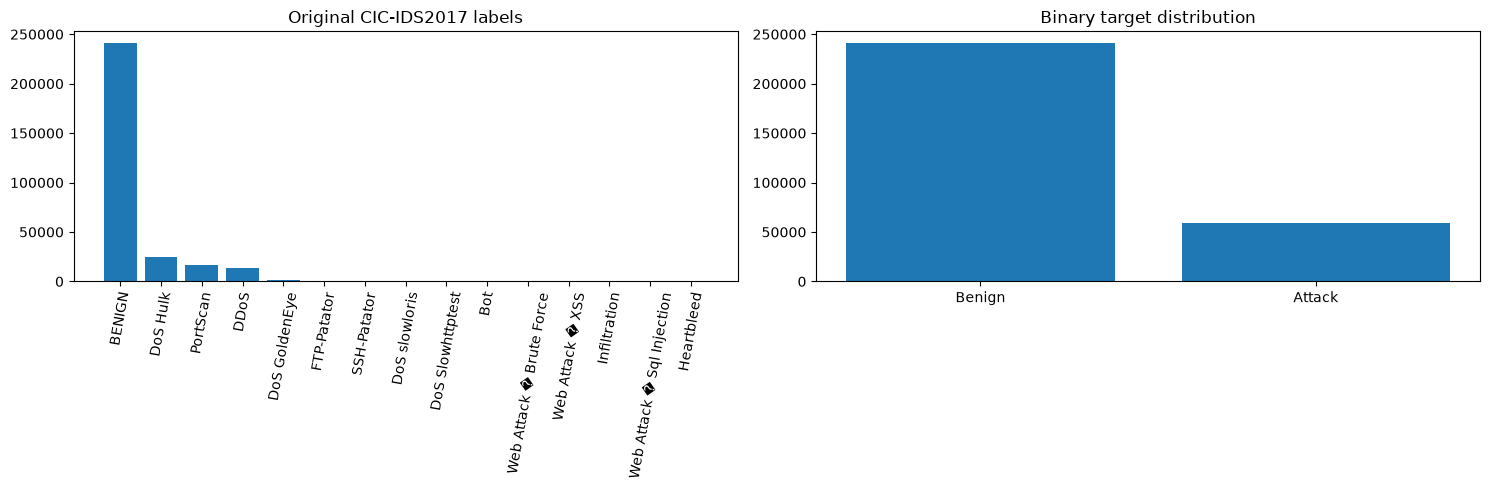

In [9]:
label_matches = [c for c in data.columns if c.strip().lower() == "label"]
if len(label_matches) != 1:
    raise ValueError(f"Expected one Label field, found {label_matches}")
LABEL_COLUMN = label_matches[0]

data["label_original"] = data[LABEL_COLUMN].astype("string").str.strip()
data["label_original"] = data["label_original"].mask(data["label_original"].eq(""), pd.NA)
missing_label_count = int(data["label_original"].isna().sum())
data = data.loc[data["label_original"].notna()].copy()
data["label_normalized"] = data["label_original"].str.upper()
data["target"] = (data["label_normalized"] != "BENIGN").astype("int8")

original_label_counts = (
    data["label_original"].value_counts().rename_axis("original_label")
    .reset_index(name="count")
)
binary_counts = data["target"].value_counts().reindex([0, 1], fill_value=0)

print("Missing-label rows excluded:", missing_label_count)
display(original_label_counts)
display(binary_counts.rename(index={0: "Benign (0)", 1: "Attack (1)"}).to_frame("count"))
save_table(original_label_counts, "original_label_counts.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(original_label_counts["original_label"], original_label_counts["count"])
axes[0].set_title("Original CIC-IDS2017 labels")
axes[0].tick_params(axis="x", rotation=80)
axes[1].bar(["Benign", "Attack"], [binary_counts.loc[0], binary_counts.loc[1]])
axes[1].set_title("Binary target distribution")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "label_distributions.png", dpi=180)
plt.show()

## 11. Feature typing and deterministic conversion

`Flow ID`, IP addresses, timestamp, and the notebook-added `source_file` column are metadata rather than predictor columns. `source_file` explains why the loaded frame has 80 columns although each original CSV has 79: it is intentionally added during ingestion to preserve row provenance. `Protocol` is categorical even though CICFlowMeter records it as a number. Source/destination ports are kept initially but scrutinized as potential dataset-specific shortcuts.

In [10]:
drop_lower = IDENTIFIER_COLUMNS | LABEL_NAMES
drop_columns = [
    c for c in data.columns
    if c.strip().lower() in drop_lower or c.strip().lower().startswith("unnamed:")
]
candidate_columns = [c for c in data.columns if c not in drop_columns]
protocol_matches = [c for c in candidate_columns if c.strip().lower() == "protocol"]
if len(protocol_matches) > 1:
    raise ValueError(f"Multiple Protocol columns: {protocol_matches}")
PROTOCOL_COLUMN = protocol_matches[0] if protocol_matches else None

NUMERIC_FEATURES = [c for c in candidate_columns if c != PROTOCOL_COLUMN]
conversion_rows = []
for col in NUMERIC_FEATURES:
    raw = data[col].astype("string").str.strip().replace("", pd.NA)
    nonmissing_before = int(raw.notna().sum())
    converted = pd.to_numeric(raw, errors="coerce")
    failed = nonmissing_before - int(converted.notna().sum())
    conversion_rows.append({
        "feature": col, "nonmissing_before": nonmissing_before,
        "coerced_to_missing": failed
    })
    data[col] = converted.replace([np.inf, -np.inf], np.nan).astype("float32")

CATEGORICAL_FEATURES = [PROTOCOL_COLUMN] if PROTOCOL_COLUMN else []
if PROTOCOL_COLUMN:
    p = data[PROTOCOL_COLUMN].astype("string").str.strip()
    p = p.mask(p.eq(""), pd.NA)
    # Convert pandas StringDtype missing markers to NumPy NaN for sklearn SimpleImputer.
    data[PROTOCOL_COLUMN] = pd.Series(
        p.to_numpy(dtype=object, na_value=np.nan), index=data.index, dtype=object
    )

conversion_audit_df = pd.DataFrame(conversion_rows).sort_values("coerced_to_missing", ascending=False)
display(conversion_audit_df.head(30))
save_table(conversion_audit_df, "numeric_conversion_audit.csv")
if (conversion_audit_df["coerced_to_missing"] > 0).any():
    warnings.warn("Unexpected predictor strings were coerced to missing; inspect the audit.")

FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES
print("Excluded metadata/target:", drop_columns)
print("Numeric feature count:", len(NUMERIC_FEATURES))
print("Categorical features:", CATEGORICAL_FEATURES)
print("Total features:", len(FEATURE_COLUMNS))

,feature,nonmissing_before,coerced_to_missing
0,Destination Port,300000,0
1,Flow Duration,300000,0
2,Total Fwd Packets,300000,0
3,Total Backward Packets,300000,0
4,Total Length of Fwd Packets,300000,0
5,Total Length of Bwd Packets,300000,0
6,Fwd Packet Length Max,300000,0
7,Fwd Packet Length Min,300000,0
8,Fwd Packet Length Mean,300000,0
9,Fwd Packet Length Std,300000,0


Excluded metadata/target: ['Label', 'source_file', 'label_original', 'label_normalized', 'target']
Numeric feature count: 78
Categorical features: []
Total features: 78


## 12. EDA and data-quality audit

We report missingness, numeric ranges, skewness, constant features, duplicates, and conflicting labels for identical feature vectors. IQR outlier flags are diagnostic only; they do not delete rows.
**Scope note:** with `MAX_ROWS_FOR_MODELING=200_000`, these row-level EDA and duplicate statistics describe the reproducible modeling sample, not every one of the 2,830,743 raw records. The label distribution in Section 8 is computed over all raw CSV rows using chunked reading. We retain this full-corpus versus sample distinction in the paper; do not report sample-only duplicate counts as full-dataset counts.


,missing_count,missing_percent
Flow Packets/s,298,0.099333
Flow Bytes/s,298,0.099333
Total Fwd Packets,0,0.000000
Total Backward Packets,0,0.000000
Destination Port,0,0.000000
Flow Duration,0,0.000000
Fwd Packet Length Max,0,0.000000
Fwd Packet Length Min,0,0.000000
Fwd Packet Length Mean,0,0.000000
Fwd Packet Length Std,0,0.000000


,count,mean,std,min,1%,25%,50%,75%,99%,max,skewness
Destination Port,300000.0,8.076455e+03,1.828117e+04,0.000000e+00,22.000000,53.000000,80.000000,4.430000e+02,6.157701e+04,6.553500e+04,2.070365
Flow Duration,300000.0,1.475343e+07,3.361239e+07,-2.000000e+00,1.000000,155.000000,31340.000000,3.231609e+06,1.177668e+08,1.200000e+08,2.158994
Total Fwd Packets,300000.0,1.027883e+01,9.003365e+02,1.000000e+00,1.000000,2.000000,2.000000,5.000000e+00,4.800000e+01,2.186580e+05,221.631027
Total Backward Packets,300000.0,1.160624e+01,1.213297e+03,0.000000e+00,0.000000,1.000000,2.000000,4.000000e+00,5.600000e+01,2.912600e+05,221.918503
Total Length of Fwd Packets,300000.0,5.987463e+02,2.443445e+04,0.000000e+00,0.000000,12.000000,62.000000,1.870000e+02,1.159500e+04,1.290000e+07,492.840118
Total Length of Bwd Packets,300000.0,1.857723e+04,2.649771e+06,0.000000e+00,0.000000,1.000000,122.000000,4.800000e+02,7.072315e+04,6.410014e+08,221.664764
Fwd Packet Length Max,300000.0,2.094288e+02,7.317573e+02,0.000000e+00,0.000000,6.000000,37.000000,8.200000e+01,3.031010e+03,2.482000e+04,9.915516
Fwd Packet Length Min,300000.0,1.862866e+01,5.903476e+01,0.000000e+00,0.000000,0.000000,2.000000,3.600000e+01,7.700000e+01,2.065000e+03,20.323866
Fwd Packet Length Mean,300000.0,5.878184e+01,1.893662e+02,0.000000e+00,0.000000,6.000000,34.000000,5.000000e+01,1.143138e+03,3.991943e+03,9.048999
Fwd Packet Length Std,300000.0,6.978970e+01,2.873069e+02,0.000000e+00,0.000000,0.000000,0.000000,2.616295e+01,1.128988e+03,6.692645e+03,10.510470


,exact_full_row_duplicates,exact_feature_binary_target_duplicates,distinct_feature_vectors_with_conflicting_binary_labels,distinct_feature_vectors_with_multiple_original_attack_labels,constant_features_in_full_data_eda_only,rows
0,12745,16110,16,16,"['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg By...",300000


No duplicates removed; duplicates remain visible for split/leakage analysis.


,feature,iqr_flagged_count,iqr_flagged_pct,q01,median,q99
21,Fwd IAT Mean,71253,23.751000,0.0,31.500000,5.510000e+07
23,Fwd IAT Max,70735,23.578333,0.0,45.000000,9.990000e+07
20,Fwd IAT Total,70570,23.523333,0.0,45.000000,1.180000e+08
9,Fwd Packet Length Std,70508,23.502667,0.0,0.000000,1.128988e+03
22,Fwd IAT Std,69874,23.291333,0.0,0.000000,4.430000e+07
6,Fwd Packet Length Max,69438,23.146000,0.0,37.000000,3.031010e+03
42,Packet Length Variance,69328,23.109333,0.0,691.200012,8.593279e+06
13,Bwd Packet Length Std,69233,23.077667,0.0,0.000000,4.128319e+03
10,Bwd Packet Length Max,67433,22.477667,0.0,79.000000,8.760000e+03
0,Destination Port,66534,22.178000,22.0,80.000000,6.157701e+04


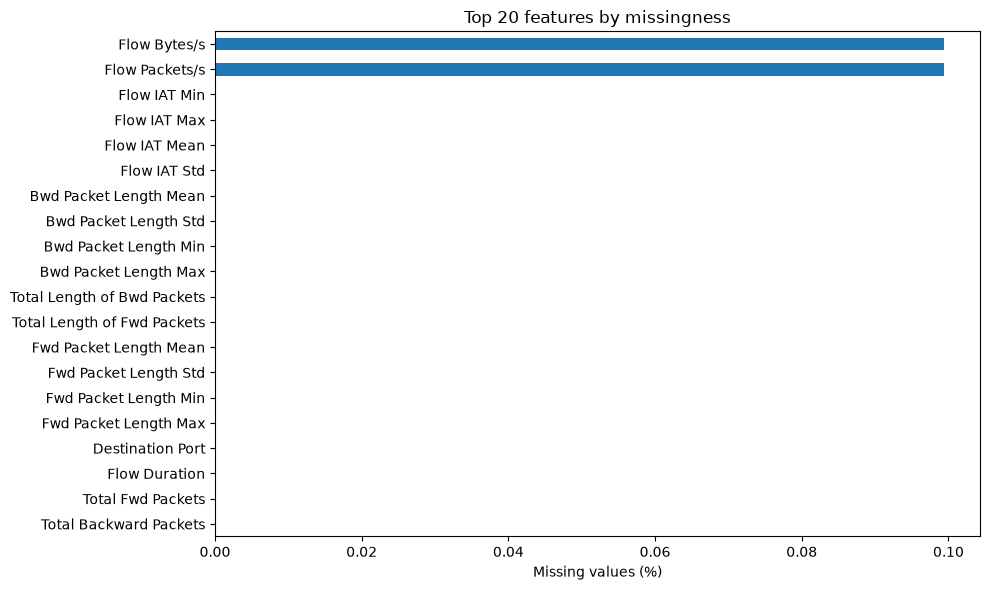

In [11]:
missing_summary = data[FEATURE_COLUMNS].isna().sum().sort_values(ascending=False).to_frame("missing_count")
missing_summary["missing_percent"] = 100 * missing_summary["missing_count"] / max(1, len(data))
display(missing_summary.head(40))
save_table(missing_summary.reset_index(names="feature"), "feature_missingness.csv")

numeric_summary = data[NUMERIC_FEATURES].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T
numeric_summary["skewness"] = data[NUMERIC_FEATURES].skew(numeric_only=True)
display(numeric_summary.head(40))
save_table(numeric_summary.reset_index(names="feature"), "numeric_feature_summary.csv")

constant_features = [c for c in FEATURE_COLUMNS if data[c].nunique(dropna=True) <= 1]
exact_full_duplicates = int(data.duplicated().sum())
exact_feature_target_duplicates = int(data.duplicated(subset=FEATURE_COLUMNS + ["target"]).sum())

feature_hashes = pd.util.hash_pandas_object(data[FEATURE_COLUMNS], index=False).astype("uint64")
hash_label = pd.DataFrame({
    "feature_hash": feature_hashes.to_numpy(),
    "binary_target": data["target"].to_numpy(),
    "original_label": data["label_original"].astype(str).to_numpy(),
})
labels_per_vector_binary = hash_label.groupby("feature_hash")["binary_target"].nunique()
labels_per_vector_original = hash_label.groupby("feature_hash")["original_label"].nunique()
conflicting_binary_vectors = int((labels_per_vector_binary > 1).sum())
conflicting_original_label_vectors = int((labels_per_vector_original > 1).sum())

duplicate_audit = pd.DataFrame([{
    "exact_full_row_duplicates": exact_full_duplicates,
    "exact_feature_binary_target_duplicates": exact_feature_target_duplicates,
    "distinct_feature_vectors_with_conflicting_binary_labels": conflicting_binary_vectors,
    "distinct_feature_vectors_with_multiple_original_attack_labels": conflicting_original_label_vectors,
    "constant_features_in_full_data_eda_only": repr(constant_features),
    "rows": len(data),
}])
display(duplicate_audit)
save_table(duplicate_audit, "duplicate_audit.csv")

if REMOVE_EXACT_DUPLICATES:
    before = len(data)
    data = data.drop_duplicates(subset=FEATURE_COLUMNS + ["target"]).copy()
    print("Removed exact feature+binary-target duplicate rows:", before - len(data))
else:
    print("No duplicates removed; duplicates remain visible for split/leakage analysis.")

# IQR values below are descriptive audit flags only. They are NOT used to fit a clipper.
outlier_rows = []
for col in NUMERIC_FEATURES:
    s = data[col].dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())
    outlier_rows.append({
        "feature": col, "iqr_flagged_count": flagged,
        "iqr_flagged_pct": 100 * flagged / len(s),
        "q01": s.quantile(0.01), "median": s.median(), "q99": s.quantile(0.99)
    })
outlier_audit_df = pd.DataFrame(outlier_rows).sort_values("iqr_flagged_pct", ascending=False)
display(outlier_audit_df.head(30))
save_table(outlier_audit_df, "iqr_outlier_audit.csv")

fig, ax = plt.subplots(figsize=(10, 6))
missing_summary.head(20).sort_values("missing_percent")["missing_percent"].plot(kind="barh", ax=ax)
ax.set_title("Top 20 features by missingness")
ax.set_xlabel("Missing values (%)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "missingness_top20.png", dpi=180)
plt.show()

## 13. Split strategy: choose by the generalization question

- **Stratified random:** conventional IID row-level benchmark.
- **Duplicate-grouped:** identical modeling feature vectors stay together; this does not remove shared five-tuples or temporal dependence.
- **Chronological:** train on earlier rows and evaluate on later rows. On CIC-IDS2017, attack schedules differ by day, so a temporal split is also a scenario-shift experiment.

These alternatives are not optimized by score. Choose one before training and interpret the result accordingly.

In [12]:
def make_holdout_indices(X, y, strategy, timestamp=None, groups=None):
    indices = np.arange(len(X))
    if strategy == "stratified_random":
        train_val, test = train_test_split(
            indices, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
        )
        val_fraction = VALIDATION_SIZE / (1 - TEST_SIZE)
        train, val = train_test_split(
            train_val, test_size=val_fraction, random_state=RANDOM_STATE,
            stratify=np.asarray(y)[train_val]
        )
    elif strategy == "duplicate_grouped":
        if groups is None:
            raise ValueError("Duplicate groups are required.")
        splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
        splits = list(splitter.split(X, y, groups))
        train_val, test = min(splits, key=lambda s: abs(len(s[1])/len(X) - TEST_SIZE))
        inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)
        inner_splits = list(inner.split(
            X.iloc[train_val], np.asarray(y)[train_val], np.asarray(groups)[train_val]
        ))
        tr_rel, val_rel = min(
            inner_splits,
            key=lambda s: abs(len(s[1])/len(train_val) - VALIDATION_SIZE/(1-TEST_SIZE))
        )
        train, val = np.asarray(train_val)[tr_rel], np.asarray(train_val)[val_rel]
    elif strategy == "chronological":
        if timestamp is None:
            raise ValueError("Timestamp column is required for chronological split.")
        parsed = pd.to_datetime(timestamp, errors="coerce")
        if parsed.isna().any():
            raise ValueError("Invalid timestamps: cannot perform chronological split.")
        order = np.argsort(parsed.to_numpy())
        n = len(order)
        train_end = int(n * (1 - TEST_SIZE - VALIDATION_SIZE))
        val_end = int(n * (1 - TEST_SIZE))
        train, val, test = order[:train_end], order[train_end:val_end], order[val_end:]
    else:
        raise ValueError(strategy)
    return np.asarray(train), np.asarray(val), np.asarray(test)

X_all = data[FEATURE_COLUMNS].copy()
y_all = data["target"].astype("int8").copy()
duplicate_groups = pd.util.hash_pandas_object(X_all, index=False).astype("uint64").to_numpy()
timestamp_col = next((c for c in data.columns if c.strip().lower() == "timestamp"), None)
timestamp_values = data[timestamp_col] if timestamp_col else None

if SPLIT_STRATEGY == "chronological" and MAX_ROWS_FOR_MODELING is not None:
    warnings.warn("Chronological evaluation should preferably use all rows or a time-aware sample, not a class-stratified streaming sample.")

train_idx, val_idx, test_idx = make_holdout_indices(
    X_all, y_all, SPLIT_STRATEGY, timestamp=timestamp_values, groups=duplicate_groups
)
X_train, y_train = X_all.iloc[train_idx].copy(), y_all.iloc[train_idx].copy()
X_val, y_val = X_all.iloc[val_idx].copy(), y_all.iloc[val_idx].copy()
X_test, y_test = X_all.iloc[test_idx].copy(), y_all.iloc[test_idx].copy()

GROUPS_TRAIN = duplicate_groups[train_idx]
GROUPS_VAL = duplicate_groups[val_idx]
GROUPS_TEST = duplicate_groups[test_idx]

# Do NOT remove constant/all-empty features using the entire train partition here:
# that would let CV validation folds influence a fitted preprocessing decision.
# VarianceThreshold is available as a fold-fitted selector inside the pipeline instead.
NUMERIC_FEATURES = [c for c in NUMERIC_FEATURES if c in X_train.columns]
CATEGORICAL_FEATURES = [c for c in CATEGORICAL_FEATURES if c in X_train.columns]
FEATURES = X_train.columns.tolist()

split_shapes = pd.DataFrame([
    record_shape("train", X_train, y_train),
    record_shape("validation", X_val, y_val),
    record_shape("test", X_test, y_test)
])
display(split_shapes)
save_table(split_shapes, "split_shapes.csv")

for name, y_part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(name, y_part.value_counts(normalize=True).sort_index().round(4).to_dict())
    if y_part.nunique() < 2:
        warnings.warn(f"{name} has one class; ROC-AUC/PR-AUC is undefined.")

constant_train_features = [c for c in X_train.columns if X_train[c].nunique(dropna=True) <= 1]
print("Constant/all-missing predictors observed in training partition (not globally dropped):", constant_train_features)

,stage,rows,columns,memory_mb,benign,attack
0,train,210000,78,64.086914,168631,41369
1,validation,45000,78,13.732910,36135,8865
2,test,45000,78,13.732910,36135,8865


train {0: 0.803, 1: 0.197}
validation {0: 0.803, 1: 0.197}
test {0: 0.803, 1: 0.197}
Constant/all-missing predictors observed in training partition (not globally dropped): ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


## 14. Cross-partition duplicate diagnostic and CV subset

The hash diagnostic measures exact feature-vector overlap between train and test. It is not a complete leakage audit: it does not identify near-duplicates, shared network connections, or temporal dependencies.

For chronological CV, we preserve temporal row order and do not randomly subsample the training rows. For other strategies, `SEARCH_MAX_ROWS` may cap the training-only tuning subset.

In [13]:
train_hashes = pd.util.hash_pandas_object(X_train, index=False).to_numpy()
test_hashes = pd.util.hash_pandas_object(X_test, index=False).to_numpy()
shared_hashes = np.intersect1d(np.unique(train_hashes), np.unique(test_hashes))
overlap_rate = len(shared_hashes) / max(1, len(np.unique(test_hashes)))
overlap_df = pd.DataFrame([{
    "unique_train_vectors": len(np.unique(train_hashes)),
    "unique_test_vectors": len(np.unique(test_hashes)),
    "shared_unique_vectors": len(shared_hashes),
    "shared_fraction_unique_test": overlap_rate,
    "split_strategy": SPLIT_STRATEGY,
}])
display(overlap_df)
save_table(overlap_df, "train_test_exact_vector_overlap.csv")
if len(shared_hashes):
    warnings.warn("Exact feature vectors cross train/test; interpret random-row scores cautiously.")

def make_cv():
    if CV_STRATEGY == "stratified":
        return StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    if CV_STRATEGY == "duplicate_grouped":
        return StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    if CV_STRATEGY == "chronological":
        return TimeSeriesSplit(n_splits=CV_FOLDS)
    raise ValueError(CV_STRATEGY)

CV = make_cv()
if CV_STRATEGY == "chronological":
    X_train_search, y_train_search = X_train.copy(), y_train.copy()
    GROUPS_TRAIN_SEARCH = None
else:
    X_train_search, y_train_search = stratified_search_subset(
        X_train, y_train, SEARCH_MAX_ROWS
    )
    if CV_STRATEGY == "duplicate_grouped":
        group_series = pd.Series(GROUPS_TRAIN, index=X_train.index)
        GROUPS_TRAIN_SEARCH = group_series.loc[X_train_search.index].to_numpy()
    else:
        GROUPS_TRAIN_SEARCH = None

print("Train:", X_train.shape, "| search subset:", X_train_search.shape)
print("CV splitter:", CV)

,unique_train_vectors,unique_test_vectors,shared_unique_vectors,shared_fraction_unique_test,split_strategy
0,200016,43629,1570,0.035985,stratified_random


Train: (210000, 78) | search subset: (25000, 78)
CV splitter: StratifiedKFold(n_splits=3, random_state=42, shuffle=True)


C:\Users\BSM Computer\AppData\Local\Temp\ipykernel_26300\1577336810.py:15: UserWarning: Exact feature vectors cross train/test; interpret random-row scores cautiously.
  warnings.warn("Exact feature vectors cross train/test; interpret random-row scores cautiously.")


## 15. Reusable classes: train-fitted outlier clipping and fold-aware XGBoost weighting

`QuantileClipper` learns bounds on the training fold only. `FoldAwareXGBClassifier` calculates `scale_pos_weight` inside each `.fit()`, so each CV fold uses its own training-label counts.

In [14]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Fit per-feature quantile caps on the current training fold only."""
    def __init__(self, lower_quantile=0.01, upper_quantile=0.99):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        arr = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(arr, self.lower_quantile, axis=0)
        self.upper_bounds_ = np.nanquantile(arr, self.upper_quantile, axis=0)
        self.n_features_in_ = arr.shape[1]
        return self

    def transform(self, X):
        arr = np.asarray(X, dtype=float)
        return np.clip(arr, self.lower_bounds_, self.upper_bounds_)

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return np.asarray([f"x{i}" for i in range(self.n_features_in_)], dtype=object)
        return np.asarray(input_features, dtype=object)


class FoldAwareXGBClassifier(ClassifierMixin, BaseEstimator):
    """XGBoost wrapper that estimates scale_pos_weight from each fit fold."""
    def __init__(
        self, n_estimators=60, max_depth=6, learning_rate=0.1,
        min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=1.0, balance_classes=False, random_state=42, n_jobs=-1
    ):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.min_child_weight = min_child_weight
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.reg_lambda = reg_lambda
        self.balance_classes = balance_classes
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        y = np.asarray(y)
        neg, pos = int(np.sum(y == 0)), int(np.sum(y == 1))
        pos_weight = neg / max(pos, 1) if self.balance_classes else 1.0
        self.estimator_ = XGBClassifier(
            objective="binary:logistic", eval_metric="logloss", tree_method="hist",
            n_estimators=self.n_estimators, max_depth=self.max_depth,
            learning_rate=self.learning_rate, min_child_weight=self.min_child_weight,
            subsample=self.subsample, colsample_bytree=self.colsample_bytree,
            reg_lambda=self.reg_lambda, scale_pos_weight=pos_weight,
            random_state=self.random_state, n_jobs=self.n_jobs,
        )
        self.estimator_.fit(X, y)
        self.classes_ = self.estimator_.classes_
        self.n_features_in_ = getattr(self.estimator_, "n_features_in_", np.asarray(X).shape[1])
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

    @property
    def feature_importances_(self):
        return self.estimator_.feature_importances_


@dataclass(frozen=True)
class PreprocessingConfig:
    numeric_imputation: str = "median"
    add_missing_indicator: bool = False
    categorical_imputation: str = "most_frequent"
    protocol_encoding: str = "onehot"
    outlier_treatment: str = "none"
    numeric_transform: str = "none"
    scaling: str = "none"
    feature_selection: str = "none"
    selector_k: int = 20


@dataclass(frozen=True)
class ExperimentConfig:
    model_name: str
    preprocessing: PreprocessingConfig
    imbalance_strategy: str = "none"

    @property
    def key(self):
        return f"{self.model_name}|{self.imbalance_strategy}|{self.preprocessing}"

## 16. Factory functions: preprocessing, encoders, and model pipeline

In [15]:
def make_numeric_pipeline(
    imputation="median", add_indicator=False, outlier="none",
    numeric_transform="none", scaling="none"
):
    imputer = SimpleImputer(
        strategy=imputation,
        fill_value=0 if imputation == "constant" else None,
        add_indicator=add_indicator,
        keep_empty_features=True,
    )
    outlier_map = {
        "none": "passthrough",
        "clip_1_99": QuantileClipper(0.01, 0.99),
        "clip_05_995": QuantileClipper(0.005, 0.995),
    }
    transform_map = {
        "none": "passthrough",
        "yeo_johnson": PowerTransformer(method="yeo-johnson", standardize=False),
    }
    scaler_map = {
        "none": "passthrough",
        "standard": StandardScaler(),
        "robust": RobustScaler(),
        "minmax": MinMaxScaler(),
    }
    if outlier not in outlier_map or numeric_transform not in transform_map or scaling not in scaler_map:
        raise ValueError("Unknown imputation, outlier, distribution-transform, or scaling method.")
    return Pipeline([
        ("imputer", imputer),
        ("outlier", outlier_map[outlier]),
        ("transform", transform_map[numeric_transform]),
        ("scaler", scaler_map[scaling]),
    ])


def make_categorical_pipeline(imputation="most_frequent"):
    if imputation == "most_frequent":
        imputer = SimpleImputer(strategy="most_frequent", keep_empty_features=True)
    elif imputation == "constant":
        imputer = SimpleImputer(strategy="constant", fill_value="Missing", keep_empty_features=True)
    else:
        raise ValueError(imputation)
    return Pipeline([
        ("imputer", imputer),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)),
    ])


def make_preprocessor(config):
    transformers = []
    if NUMERIC_FEATURES:
        transformers.append((
            "numeric",
            make_numeric_pipeline(
                config.numeric_imputation, config.add_missing_indicator,
                config.outlier_treatment, config.numeric_transform, config.scaling
            ),
            NUMERIC_FEATURES,
        ))
    if CATEGORICAL_FEATURES:
        cat = (
            make_categorical_pipeline(config.categorical_imputation)
            if config.protocol_encoding == "onehot" else "drop"
        )
        transformers.append(("categorical", cat, CATEGORICAL_FEATURES))
    if not transformers:
        raise ValueError("No feature transformers remain.")
    return ColumnTransformer(
        transformers, remainder="drop", sparse_threshold=0.0,
        verbose_feature_names_out=False
    )


def make_classifier(model_name):
    if model_name == "Logistic Regression":
        return LogisticRegression(
            solver="lbfgs", max_iter=3000, class_weight=None,
            random_state=RANDOM_STATE
        )
    if model_name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=BASE_RF_ESTIMATORS, class_weight=None,
            n_jobs=MODEL_N_JOBS, random_state=RANDOM_STATE
        )
    if model_name == "XGBoost":
        if not XGBOOST_AVAILABLE:
            raise ImportError("Install through UV: uv add xgboost")
        return FoldAwareXGBClassifier(
            n_estimators=BASE_XGB_ESTIMATORS, max_depth=6, learning_rate=0.1,
            random_state=RANDOM_STATE, n_jobs=MODEL_N_JOBS
        )
    raise ValueError(model_name)


def make_model_pipeline(model_name, preprocessing):
    return ImbPipeline([
        ("preprocessor", make_preprocessor(preprocessing)),
        ("sampler", "passthrough"),
        ("selector", "passthrough"),
        ("model", make_classifier(model_name)),
    ])


def evaluate_model(estimator, X_fit, y_fit, X_eval, y_eval, label):
    fitted = clone(estimator)
    fit_start = time.perf_counter()
    fitted.fit(X_fit, y_fit)
    fit_seconds = time.perf_counter() - fit_start
    pred_start = time.perf_counter()
    pred = fitted.predict(X_eval)
    prob = fitted.predict_proba(X_eval)[:, 1]
    predict_seconds = time.perf_counter() - pred_start
    metrics = calculate_metrics(y_eval, pred, prob)
    metrics.update({
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
        "predict_ms_per_row": predict_seconds * 1000 / max(1, len(X_eval)),
    })
    return fitted, {"candidate": label, **metrics}

print("Factories, reusable configurations, and experiment runner are ready.")

Factories, reusable configurations, and experiment runner are ready.


## 17. Grid-search runner

Every search uses the same scoring dictionary and CV protocol. Macro-F1 is the refit metric; Attack recall and FPR are inspected as additional operating characteristics.

In [16]:
def run_grid_search(estimator, param_grid, X_fit, y_fit, label, groups=None, verbose=0):
    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring=SCORING,
        refit=PRIMARY_SCORING,
        cv=CV,
        n_jobs=SEARCH_N_JOBS,
        verbose=verbose,
        error_score=np.nan,
        return_train_score=False,
        pre_dispatch="1*n_jobs",
    )
    kwargs = {"groups": groups} if groups is not None else {}
    start = time.perf_counter()
    search.fit(X_fit, y_fit, **kwargs)
    elapsed = time.perf_counter() - start
    results = pd.DataFrame(search.cv_results_)
    results["search_label"] = label
    results["search_seconds"] = elapsed
    results = results.sort_values("rank_test_f1_macro")
    return search, results, elapsed


def current_cv_groups():
    return GROUPS_TRAIN_SEARCH if CV_STRATEGY == "duplicate_grouped" else None


def mutual_info_score_func(X, y):
    return mutual_info_classif(X, y, random_state=RANDOM_STATE)

## 18. Stage 0 — default baseline benchmark

Baseline: median imputation, one-hot Protocol, no outlier transformation, StandardScaler only for Logistic Regression, no feature selection, and no balancing.

In [17]:
MODEL_NAMES = ["Logistic Regression", "Random Forest"]
if XGBOOST_AVAILABLE:
    MODEL_NAMES.append("XGBoost")

BASE_PREPROCESSING = {
    name: PreprocessingConfig(
        numeric_imputation="median",
        add_missing_indicator=False,
        categorical_imputation="most_frequent",
        protocol_encoding="onehot",
        outlier_treatment="none",
        numeric_transform="none",
        scaling="standard" if name == "Logistic Regression" else "none",
    )
    for name in MODEL_NAMES
}

baseline_rows = []
baseline_fitted = {}
for name in MODEL_NAMES:
    print("\\nBaseline CV:", name)
    pipe = make_model_pipeline(name, BASE_PREPROCESSING[name])
    cv_scores = cross_validate(
        pipe, X_train_search, y_train_search,
        scoring=SCORING, cv=CV, n_jobs=SEARCH_N_JOBS,
        groups=current_cv_groups(), return_train_score=False
    )
    fitted, val = evaluate_model(pipe, X_train, y_train, X_val, y_val, f"{name}|baseline")
    baseline_fitted[name] = fitted
    baseline_rows.append({
        "model": name,
        "cv_f1_macro_mean": float(np.nanmean(cv_scores["test_f1_macro"])),
        "cv_f1_macro_std": float(np.nanstd(cv_scores["test_f1_macro"], ddof=1)),
        "cv_roc_auc_mean": float(np.nanmean(cv_scores["test_roc_auc"])) if "test_roc_auc" in cv_scores else np.nan,
        "cv_average_precision_mean": float(np.nanmean(cv_scores["test_average_precision"])) if "test_average_precision" in cv_scores else np.nan,
        **{k: v for k, v in val.items() if k != "candidate"},
    })

baseline_results_df = rank_validation_results(pd.DataFrame(baseline_rows))
display(baseline_results_df)
save_table(baseline_results_df, "stage0_baseline_results.csv")

\nBaseline CV: Logistic Regression
\nBaseline CV: Random Forest
\nBaseline CV: XGBoost


,model,cv_f1_macro_mean,cv_f1_macro_std,cv_roc_auc_mean,cv_average_precision_mean,accuracy,precision_attack,recall_attack,f1_attack,f1_macro,...,mcc,false_positive_rate,false_negative_rate,TN,FP,FN,TP,fit_seconds,predict_seconds,predict_ms_per_row
0,Random Forest,0.994932,0.000771,0.999501,0.998105,0.998289,0.996946,0.994360,0.995651,0.997293,...,0.994588,0.000747,0.005640,36108,27,50,8815,10.601204,0.157493,0.003500
1,XGBoost,0.994939,0.000114,0.999682,0.998847,0.998044,0.995484,0.994585,0.995034,0.996908,...,0.993817,0.001107,0.005415,36095,40,48,8817,2.014522,0.094832,0.002107
2,Logistic Regression,0.905009,0.001715,0.982175,0.937264,0.941289,0.856048,0.843880,0.849920,0.906713,...,0.813461,0.034814,0.156120,34877,1258,1384,7481,8.103198,0.096474,0.002144


WindowsPath('E:/03 Education/Zagazig Material/Masters/First Year First Term/Machine Learning/Research Paper/ML for Intrusion Detection/reports/tables/stage0_baseline_results.csv')

## 19. Stage 1 — imbalance strategy search

Compare none, class weighting, RandomOverSampler, and RandomUnderSampler. Resampling is inside the imbalanced-learn pipeline and therefore runs only on each CV training fold. We do not combine weights and sampling in one candidate.

In [18]:
def make_imbalance_grid(model_name):
    if model_name == "Logistic Regression":
        weight_grid = {"sampler": ["passthrough"], "model__class_weight": [None, "balanced"]}
        sampler_grid = {
            "sampler": [RandomOverSampler(random_state=RANDOM_STATE),
                        RandomUnderSampler(random_state=RANDOM_STATE)],
            "model__class_weight": [None],
        }
    elif model_name == "Random Forest":
        weight_grid = {"sampler": ["passthrough"], "model__class_weight": [None, "balanced_subsample"]}
        sampler_grid = {
            "sampler": [RandomOverSampler(random_state=RANDOM_STATE),
                        RandomUnderSampler(random_state=RANDOM_STATE)],
            "model__class_weight": [None],
        }
    else:
        weight_grid = {"sampler": ["passthrough"], "model__balance_classes": [False, True]}
        sampler_grid = {
            "sampler": [RandomOverSampler(random_state=RANDOM_STATE),
                        RandomUnderSampler(random_state=RANDOM_STATE)],
            "model__balance_classes": [False],
        }
    return [weight_grid, sampler_grid]

imbalance_searches = {}
imbalance_cv_frames = []
imbalance_val_rows = []
imbalance_fitted_pipelines = {}

for name in MODEL_NAMES:
    base = make_model_pipeline(name, BASE_PREPROCESSING[name])
    search, cv_frame, elapsed = run_grid_search(
        base, make_imbalance_grid(name), X_train_search, y_train_search,
        f"imbalance|{name}", groups=current_cv_groups()
    )
    imbalance_searches[name] = search
    cv_frame["model"] = name
    imbalance_cv_frames.append(cv_frame)

    fitted, val = evaluate_model(
        search.best_estimator_, X_train, y_train, X_val, y_val, f"{name}|best_imbalance"
    )
    imbalance_fitted_pipelines[name] = fitted
    imbalance_val_rows.append({
        **{k: v for k, v in val.items() if k != "candidate"},
        "model": name,
        "best_params": repr(search.best_params_),
        "cv_best_f1_macro": float(search.best_score_),
        "search_seconds": elapsed,
    })

imbalance_cv_df = pd.concat(imbalance_cv_frames, ignore_index=True)
imbalance_validation_df = rank_validation_results(pd.DataFrame(imbalance_val_rows))
display(imbalance_validation_df)
save_table(imbalance_cv_df, "stage1_imbalance_cv_candidates.csv")
save_table(imbalance_validation_df, "stage1_imbalance_validation.csv")

,accuracy,precision_attack,recall_attack,f1_attack,f1_macro,f1_weighted,balanced_accuracy,roc_auc,average_precision,mcc,...,FP,FN,TP,fit_seconds,predict_seconds,predict_ms_per_row,model,best_params,cv_best_f1_macro,search_seconds
0,0.998400,0.996724,0.995149,0.995936,0.997470,0.998400,0.997173,0.999730,0.998229,0.994940,...,29,43,8822,24.147207,0.158646,0.003525,Random Forest,"{'model__class_weight': None, 'sampler': Rando...",0.995313,5.971833
1,0.998044,0.995484,0.994585,0.995034,0.996908,0.998044,0.996739,0.999856,0.999366,0.993817,...,40,48,8817,2.354546,0.106935,0.002376,XGBoost,"{'model__balance_classes': False, 'sampler': '...",0.994939,4.003997
2,0.917378,0.716497,0.960745,0.820837,0.883573,0.921591,0.933742,0.978078,0.915954,0.782581,...,3370,348,8517,11.260465,0.068239,0.001516,Logistic Regression,"{'model__class_weight': None, 'sampler': Rando...",0.910786,4.008190


WindowsPath('E:/03 Education/Zagazig Material/Masters/First Year First Term/Machine Learning/Research Paper/ML for Intrusion Detection/reports/tables/stage1_imbalance_validation.csv')

## 20. Stage 2 — preprocessing sensitivity grids

Each factor is searched separately for each classifier, holding the other selected components fixed.

- Numeric imputation: median / mean / constant zero, with or without a missing indicator.
- Outliers: none / quantile clipping; Yeo-Johnson is also tested for Logistic Regression.
- Protocol: one-hot / feature ablation (drop).
- Scaling: none / Standard / Robust / MinMax for Logistic Regression only.
- Feature selection: none / ANOVA top-20 / ANOVA top-40; mutual information is opt-in.
- Categorical imputation is searched only if Protocol actually has missing values.

In [19]:
def selector_candidates(max_features):
    """Candidate selectors fit inside each CV fold; no full-dataset feature selection."""
    opts = ["passthrough"]
    opts.append(VarianceThreshold(threshold=0.0))
    for k in [10, 20, 40]:
        if 1 <= k < max_features:
            opts.append(SelectKBest(score_func=f_classif, k=k))
    if INCLUDE_MUTUAL_INFO_IN_SEARCH:
        for k in [10, 20]:
            if 1 <= k < max_features:
                opts.append(SelectKBest(score_func=mutual_info_score_func, k=k))
    return opts


def make_preprocessing_factor_grids(model_name):
    encoded_upper = len(NUMERIC_FEATURES) + (
        int(X_train[PROTOCOL_COLUMN].nunique(dropna=True))
        if PROTOCOL_COLUMN in CATEGORICAL_FEATURES else 0
    )
    grids = {
        "numeric_imputation": {
            "preprocessor__numeric__imputer__strategy": ["median", "mean", "constant"],
            "preprocessor__numeric__imputer__add_indicator": [False, True],
        },
        "outlier_treatment": {
            "preprocessor__numeric__outlier": [
                "passthrough", QuantileClipper(0.01, 0.99), QuantileClipper(0.005, 0.995)
            ],
        },
        "feature_selection": {"selector": selector_candidates(encoded_upper)},
    }
    if model_name == "Logistic Regression":
        grids["numeric_transform"] = {
            "preprocessor__numeric__transform": [
                "passthrough", PowerTransformer(method="yeo-johnson", standardize=False)
            ]
        }
        grids["scaling"] = {
            "preprocessor__numeric__scaler": [
                StandardScaler(), RobustScaler(), MinMaxScaler(), "passthrough"
            ]
        }
    # Protocol is low-cardinality nominal: one-hot is the meaningful encoding.
    # Dropping it is retained as a feature-ablation experiment, not an alternative encoder.
    if CATEGORICAL_FEATURES:
        grids["protocol_handling"] = {
            "preprocessor__categorical": [make_categorical_pipeline("most_frequent"), "drop"]
        }
        if X_train[CATEGORICAL_FEATURES].isna().any().any():
            grids["categorical_imputation"] = {
                "preprocessor__categorical__imputer__strategy": ["most_frequent", "constant"],
            }
    return grids


preprocessing_searches = {}
preprocessing_cv_frames = []
preprocessing_winners = {}
preprocessing_validation_rows = []

for name in MODEL_NAMES:
    print("\\nPreprocessing sensitivity:", name)
    base = clone(imbalance_searches[name].best_estimator_)
    winners = {}

    for factor, grid in make_preprocessing_factor_grids(name).items():
        print("  Searching:", factor)
        # If Protocol is dropped, its conditional imputation parameter cannot be merged later.
        search, cv_frame, elapsed = run_grid_search(
            clone(base), grid, X_train_search, y_train_search,
            f"preprocessing|{name}|{factor}", groups=current_cv_groups()
        )
        preprocessing_searches[(name, factor)] = search
        winners[factor] = search.best_params_
        cv_frame["model"] = name
        cv_frame["factor"] = factor
        preprocessing_cv_frames.append(cv_frame)

        fitted, val = evaluate_model(
            search.best_estimator_, X_train, y_train, X_val, y_val,
            f"{name}|{factor}"
        )
        preprocessing_validation_rows.append({
            **{k: v for k, v in val.items() if k != "candidate"},
            "model": name,
            "factor": factor,
            "cv_best_f1_macro": float(search.best_score_),
            "best_params": repr(search.best_params_),
            "search_seconds": elapsed,
        })

    preprocessing_winners[name] = winners

preprocessing_cv_df = pd.concat(preprocessing_cv_frames, ignore_index=True)
preprocessing_validation_df = pd.DataFrame(preprocessing_validation_rows)
display(preprocessing_validation_df.sort_values(["model", "f1_macro"], ascending=[True, False]))
save_table(preprocessing_cv_df, "stage2_preprocessing_cv_candidates.csv")
save_table(preprocessing_validation_df, "stage2_preprocessing_validation.csv")

\nPreprocessing sensitivity: Logistic Regression
  Searching: numeric_imputation
  Searching: outlier_treatment
  Searching: feature_selection


e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [31 33 56 57 58 59 60 61] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [31 33 56 57 58 59 60 61] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
e:\03 Education\Zagazig Material\Maste

  Searching: numeric_transform
  Searching: scaling


e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIM

\nPreprocessing sensitivity: Random Forest
  Searching: numeric_imputation
  Searching: outlier_treatment
  Searching: feature_selection


e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [31 33 56 57 58 59 60 61] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [31 33 56 57 58 59 60 61] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
e:\03 Education\Zagazig Material\Maste

\nPreprocessing sensitivity: XGBoost
  Searching: numeric_imputation
  Searching: outlier_treatment
  Searching: feature_selection


e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [31 33 56 57 58 59 60 61] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
e:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [31 33 56 57 58 59 60 61] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
e:\03 Education\Zagazig Material\Maste

,accuracy,precision_attack,recall_attack,f1_attack,f1_macro,f1_weighted,balanced_accuracy,roc_auc,average_precision,mcc,...,FN,TP,fit_seconds,predict_seconds,predict_ms_per_row,model,factor,cv_best_f1_macro,best_params,search_seconds
3,0.978444,0.909195,0.989397,0.947602,0.967016,0.978782,0.982577,0.993818,0.966004,0.935386,...,94,8771,24.510225,0.171055,0.003801,Logistic Regression,numeric_transform,0.963707,{'preprocessor__numeric__transform': PowerTran...,7.114845
1,0.947689,0.805480,0.968302,0.879418,0.923009,0.949425,0.955467,0.988195,0.956418,0.852224,...,281,8584,20.255097,0.168045,0.003734,Logistic Regression,outlier_treatment,0.917225,{'preprocessor__numeric__outlier': QuantileCli...,5.341333
2,0.918267,0.718143,0.963113,0.822781,0.884833,0.922437,0.935189,0.978206,0.916276,0.785150,...,327,8538,10.925282,0.078435,0.001743,Logistic Regression,feature_selection,0.911167,{'selector': VarianceThreshold()},43.961725
0,0.917889,0.717410,0.962211,0.821971,0.884305,0.922079,0.934613,0.978064,0.915557,0.784090,...,335,8530,19.087486,0.089710,0.001994,Logistic Regression,numeric_imputation,0.911196,{'preprocessor__numeric__imputer__add_indicato...,7.683923
4,0.917378,0.716497,0.960745,0.820837,0.883573,0.921591,0.933742,0.978078,0.915954,0.782581,...,348,8517,14.146459,0.086073,0.001913,Logistic Regression,scaling,0.910786,{'preprocessor__numeric__scaler': StandardScal...,21.716770
7,0.998444,0.996612,0.995488,0.996050,0.997541,0.998444,0.997329,0.999732,0.998237,0.995081,...,40,8825,16.178939,0.158643,0.003525,Random Forest,feature_selection,0.995440,{'selector': VarianceThreshold()},48.787967
5,0.998333,0.996498,0.995037,0.995767,0.997365,0.998333,0.997089,0.999731,0.998234,0.994730,...,44,8821,22.444106,0.179016,0.003978,Random Forest,numeric_imputation,0.995503,{'preprocessor__numeric__imputer__add_indicato...,9.403488
6,0.998311,0.996385,0.995037,0.995711,0.997330,0.998311,0.997076,0.999731,0.998233,0.994659,...,44,8821,22.486908,0.217358,0.004830,Random Forest,outlier_treatment,0.995378,{'preprocessor__numeric__outlier': QuantileCli...,5.678248
10,0.998133,0.995710,0.994811,0.995260,0.997049,0.998133,0.996880,0.999864,0.999421,0.994098,...,46,8819,2.159290,0.100512,0.002234,XGBoost,feature_selection,0.995255,{'selector': VarianceThreshold()},27.871085
9,0.998067,0.995596,0.994585,0.995091,0.996943,0.998066,0.996753,0.999837,0.999234,0.993887,...,48,8817,2.727746,0.130440,0.002899,XGBoost,outlier_treatment,0.995445,{'preprocessor__numeric__outlier': QuantileCli...,3.721686


WindowsPath('E:/03 Education/Zagazig Material/Masters/First Year First Term/Machine Learning/Research Paper/ML for Intrusion Detection/reports/tables/stage2_preprocessing_validation.csv')

## 21. Stage 2b — merge and validate the combined preprocessing candidate

Individually best choices may interact. We merge their best CV parameters, refit the combined candidate on `X_train`, and compare it with the imbalance-selected baseline on `X_val`. The combined configuration is kept only if its validation ranking improves.

In [20]:
selected_pipeline_by_model = {}
combined_validation_rows = []
combined_params_by_model = {}

for name in MODEL_NAMES:
    baseline_pipe = clone(imbalance_searches[name].best_estimator_)
    combined_pipe = clone(baseline_pipe)
    merged = {}
    for factor_params in preprocessing_winners[name].values():
        merged.update(factor_params)

    # A categorical-imputation choice only applies when Protocol remains in the model.
    if merged.get("preprocessor__categorical") == "drop":
        merged = {k: v for k, v in merged.items()
                  if not k.startswith("preprocessor__categorical__")}

    if merged:
        combined_pipe.set_params(**merged)

    baseline_fit, baseline_val = evaluate_model(
        baseline_pipe, X_train, y_train, X_val, y_val, f"{name}|imbalance_baseline"
    )
    combined_fit, combined_val = evaluate_model(
        combined_pipe, X_train, y_train, X_val, y_val, f"{name}|combined_pipeline"
    )

    comparison = pd.DataFrame([
        {"candidate": "imbalance baseline", **{k:v for k,v in baseline_val.items() if k!="candidate"}},
        {"candidate": "combined preprocessing", **{k:v for k,v in combined_val.items() if k!="candidate"}},
    ])
    display(comparison[["candidate", "f1_macro", "recall_attack", "false_positive_rate", "average_precision"]])

    winner = rank_validation_results(comparison).iloc[0]["candidate"]
    selected_pipeline_by_model[name] = combined_fit if winner == "combined preprocessing" else baseline_fit
    combined_params_by_model[name] = merged

    combined_validation_rows.extend([
        {"model": name, "candidate_type": "imbalance baseline", **{k:v for k,v in baseline_val.items() if k!="candidate"}},
        {"model": name, "candidate_type": "combined preprocessing", **{k:v for k,v in combined_val.items() if k!="candidate"}},
    ])

combined_validation_df = pd.DataFrame(combined_validation_rows)
display(combined_validation_df.sort_values(["model", "f1_macro"], ascending=[True, False]))
save_table(combined_validation_df, "stage2b_combined_validation.csv")

,candidate,f1_macro,recall_attack,false_positive_rate,average_precision
0,imbalance baseline,0.883573,0.960745,0.093261,0.915954
1,combined preprocessing,0.964465,0.985110,0.025266,0.978691


,candidate,f1_macro,recall_attack,false_positive_rate,average_precision
0,imbalance baseline,0.997470,0.995149,0.000803,0.998229
1,combined preprocessing,0.997541,0.995488,0.000830,0.998350


,candidate,f1_macro,recall_attack,false_positive_rate,average_precision
0,imbalance baseline,0.996908,0.994585,0.001107,0.999366
1,combined preprocessing,0.997260,0.995375,0.001024,0.999390


,model,candidate_type,accuracy,precision_attack,recall_attack,f1_attack,f1_macro,f1_weighted,balanced_accuracy,roc_auc,...,mcc,false_positive_rate,false_negative_rate,TN,FP,FN,TP,fit_seconds,predict_seconds,predict_ms_per_row
1,Logistic Regression,combined preprocessing,0.976778,0.905349,0.985110,0.943547,0.964465,0.977141,0.979922,0.994232,...,0.930274,0.025266,0.014890,35222,913,132,8733,29.071300,0.299354,0.006652
0,Logistic Regression,imbalance baseline,0.917378,0.716497,0.960745,0.820837,0.883573,0.921591,0.933742,0.978078,...,0.782581,0.093261,0.039255,32765,3370,348,8517,11.893599,0.075305,0.001673
3,Random Forest,combined preprocessing,0.998444,0.996612,0.995488,0.996050,0.997541,0.998444,0.997329,0.999745,...,0.995081,0.000830,0.004512,36105,30,40,8825,18.025739,0.211323,0.004696
2,Random Forest,imbalance baseline,0.998400,0.996724,0.995149,0.995936,0.997470,0.998400,0.997173,0.999730,...,0.994940,0.000803,0.004851,36106,29,43,8822,19.823352,0.158473,0.003522
5,XGBoost,combined preprocessing,0.998267,0.995824,0.995375,0.995600,0.997260,0.998267,0.997176,0.999864,...,0.994520,0.001024,0.004625,36098,37,41,8824,1.729667,0.142585,0.003169
4,XGBoost,imbalance baseline,0.998044,0.995484,0.994585,0.995034,0.996908,0.998044,0.996739,0.999856,...,0.993817,0.001107,0.005415,36095,40,48,8817,2.362075,0.085575,0.001902


WindowsPath('E:/03 Education/Zagazig Material/Masters/First Year First Term/Machine Learning/Research Paper/ML for Intrusion Detection/reports/tables/stage2b_combined_validation.csv')

## 22. Stage 3 — model hyperparameter GridSearchCV

The pipeline configuration is now fixed for each model. Tune only model-level parameters.

- Logistic Regression: `C`.
- Random Forest: `n_estimators`, `max_depth`, `min_samples_leaf`.
- XGBoost: `n_estimators`, `max_depth`, `learning_rate`, `min_child_weight`.

These are compact, discrete grids. If the ranges are broadened substantially, use RandomizedSearchCV or Bayesian optimization rather than making the exhaustive grid explode.

In [21]:
def hyperparameter_grid(model_name):
    """Compact discrete model-level grid. Expand only after profiling compute cost."""
    if model_name == "Logistic Regression":
        return {"model__C": [0.1, 1.0, 10.0]}
    if model_name == "Random Forest":
        return {
            "model__n_estimators": RF_SEARCH_N_ESTIMATORS,
            "model__max_depth": [None, 20],
            "model__min_samples_leaf": [1, 3],
        }
    if model_name == "XGBoost":
        return {
            "model__n_estimators": XGB_SEARCH_N_ESTIMATORS,
            "model__max_depth": [3, 5],
            "model__learning_rate": [0.05, 0.1],
            "model__min_child_weight": [1, 5],
        }
    raise ValueError(model_name)

hyperparameter_searches = {}
hyperparameter_cv_frames = []
tuned_validation_rows = []
tuned_pipeline_by_model = {}

for name in MODEL_NAMES:
    print("\\nHyperparameter tuning:", name)
    search, cv_frame, elapsed = run_grid_search(
        clone(selected_pipeline_by_model[name]),
        hyperparameter_grid(name),
        X_train_search, y_train_search,
        f"hyperparameters|{name}", groups=current_cv_groups(), verbose=1
    )
    hyperparameter_searches[name] = search
    cv_frame["model"] = name
    hyperparameter_cv_frames.append(cv_frame)

    fitted, val = evaluate_model(
        search.best_estimator_, X_train, y_train, X_val, y_val, f"{name}|tuned"
    )
    tuned_pipeline_by_model[name] = fitted
    tuned_validation_rows.append({
        "model": name,
        "best_params": repr(search.best_params_),
        "cv_best_f1_macro": float(search.best_score_),
        "search_seconds": elapsed,
        **{k: v for k, v in val.items() if k != "candidate"},
    })

hyperparameter_cv_df = pd.concat(hyperparameter_cv_frames, ignore_index=True)
tuned_validation_df = rank_validation_results(pd.DataFrame(tuned_validation_rows))
display(tuned_validation_df)
save_table(hyperparameter_cv_df, "stage3_hyperparameter_cv_candidates.csv")
save_table(tuned_validation_df, "stage3_tuned_validation.csv")

\nHyperparameter tuning: Logistic Regression
Fitting 3 folds for each of 3 candidates, totalling 9 fits
\nHyperparameter tuning: Random Forest
Fitting 3 folds for each of 8 candidates, totalling 24 fits
\nHyperparameter tuning: XGBoost
Fitting 3 folds for each of 16 candidates, totalling 48 fits


,model,best_params,cv_best_f1_macro,search_seconds,accuracy,precision_attack,recall_attack,f1_attack,f1_macro,f1_weighted,...,mcc,false_positive_rate,false_negative_rate,TN,FP,FN,TP,fit_seconds,predict_seconds,predict_ms_per_row
0,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.996332,19.119500,0.998956,0.997181,0.997518,0.997350,0.998350,0.998956,...,0.996699,0.000692,0.002482,36110,25,22,8843,2.489861,0.157339,0.003496
1,Random Forest,"{'model__max_depth': None, 'model__min_samples...",0.995448,19.867436,0.998689,0.995722,0.997631,0.996675,0.997929,0.998689,...,0.995860,0.001052,0.002369,36097,38,21,8844,39.184412,0.308419,0.006854
2,Logistic Regression,{'model__C': 10.0},0.962335,16.952180,0.978489,0.910746,0.987592,0.947613,0.967040,0.978812,...,0.935320,0.023744,0.012408,35277,858,110,8755,31.726498,0.285695,0.006349


WindowsPath('E:/03 Education/Zagazig Material/Masters/First Year First Term/Machine Learning/Research Paper/ML for Intrusion Detection/reports/tables/stage3_tuned_validation.csv')

## 23. Select the validation champion and a tree model for SHAP

In [22]:
BEST_MODEL_NAME = str(tuned_validation_df.iloc[0]["model"])
BEST_VALIDATION_PIPELINE = tuned_pipeline_by_model[BEST_MODEL_NAME]
print("Overall validation champion:", BEST_MODEL_NAME)

tree_rows = tuned_validation_df[tuned_validation_df["model"].isin(["Random Forest", "XGBoost"])]
if tree_rows.empty:
    BEST_TREE_NAME = None
    BEST_TREE_PIPELINE = None
else:
    BEST_TREE_NAME = str(rank_validation_results(tree_rows).iloc[0]["model"])
    BEST_TREE_PIPELINE = tuned_pipeline_by_model[BEST_TREE_NAME]
    print("Tree model for SHAP:", BEST_TREE_NAME)

Overall validation champion: XGBoost
Tree model for SHAP: XGBoost


## 24. SHAP global and local explanations

SHAP is calculated on a reproducible sample from the training partition. For Random Forest, SHAP may return a class dimension; for XGBoost the default raw output is usually a margin/log-odds value. We normalize the output shape for feature ranking.

SHAP contributions explain model output; they do not establish causal relationships.

,mean_abs_shap
Init_Win_bytes_forward,1.482133
Destination Port,1.281903
Average Packet Size,0.797219
Bwd Packet Length Std,0.757259
Init_Win_bytes_backward,0.715109
Total Length of Bwd Packets,0.424307
min_seg_size_forward,0.422673
Bwd Packets/s,0.418792
Bwd Packet Length Min,0.389058
Bwd Header Length,0.375351


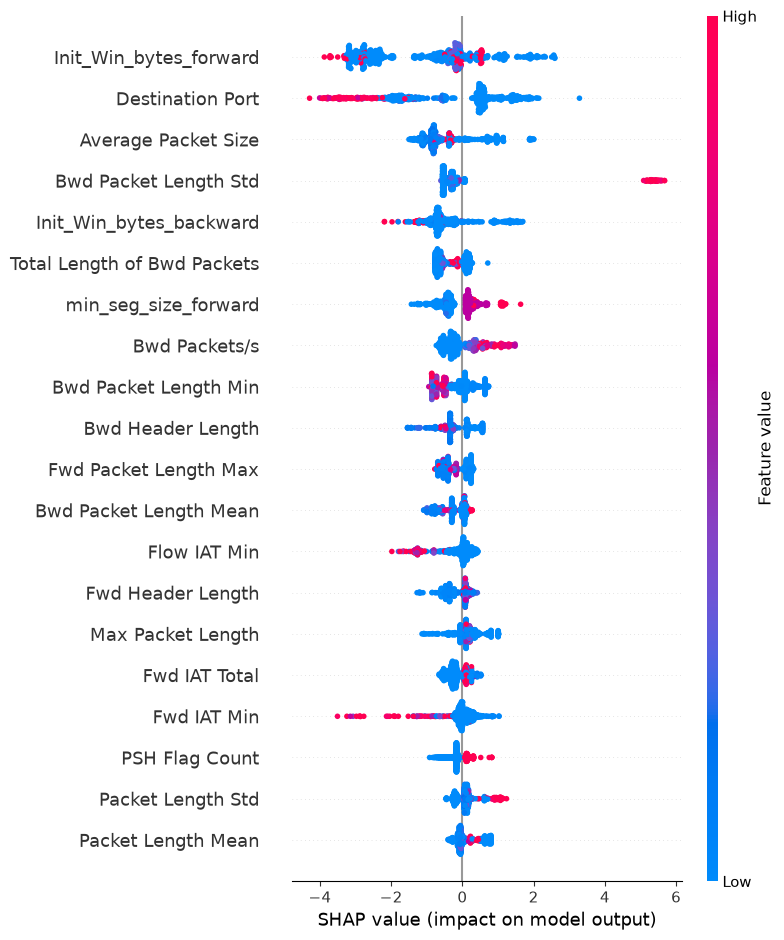

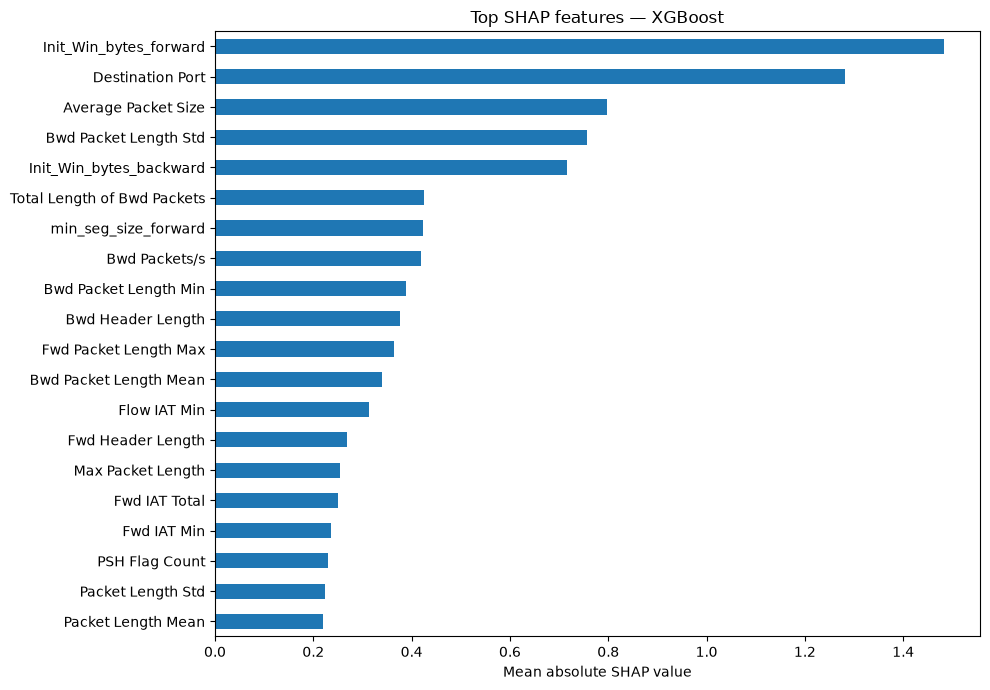

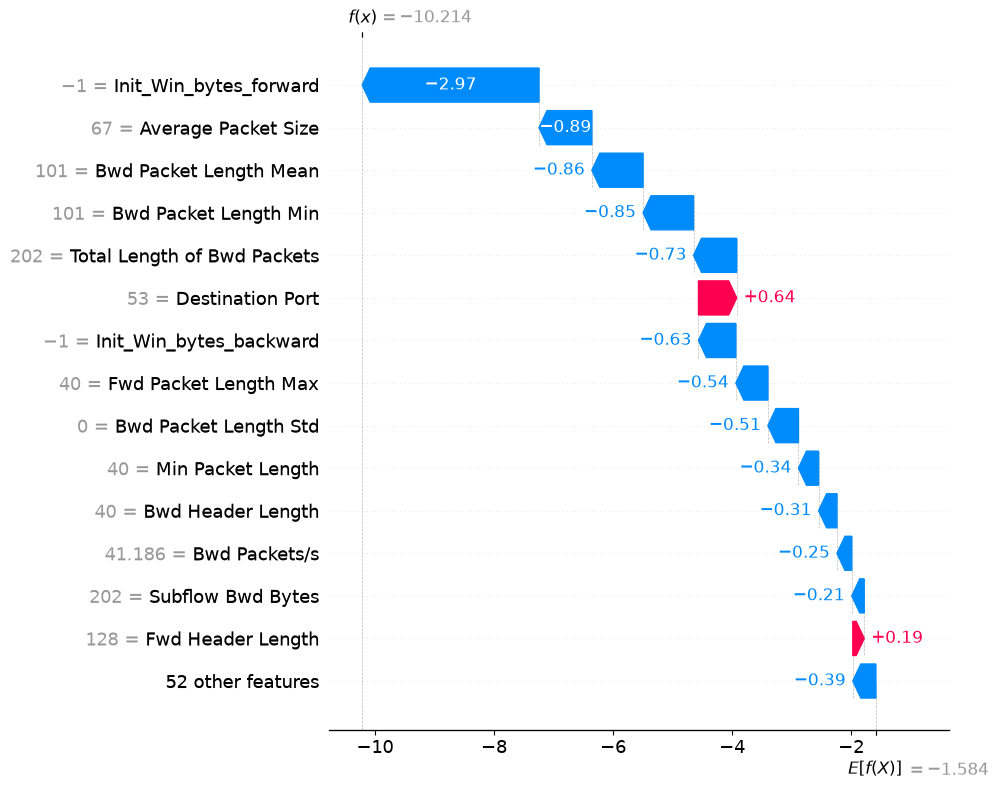

In [23]:
shap_importance = pd.Series(dtype=float)
if BEST_TREE_PIPELINE is not None and SHAP_AVAILABLE:
    pre = BEST_TREE_PIPELINE.named_steps["preprocessor"]
    selector = BEST_TREE_PIPELINE.named_steps["selector"]
    model_step = BEST_TREE_PIPELINE.named_steps["model"]
    tree_model = model_step.estimator_ if isinstance(model_step, FoldAwareXGBClassifier) else model_step

    rng = np.random.default_rng(RANDOM_STATE)
    n_shap = min(SHAP_SAMPLE_SIZE, len(X_train))
    rows = rng.choice(len(X_train), size=n_shap, replace=False)
    X_shap_raw = X_train.iloc[rows]

    X_shap_pre = pre.transform(X_shap_raw)
    transformed_names = np.asarray(pre.get_feature_names_out(), dtype=object)
    if selector != "passthrough":
        X_shap_sel = selector.transform(X_shap_pre)
        transformed_names = transformed_names[selector.get_support()]
    else:
        X_shap_sel = X_shap_pre

    explainer = shap.TreeExplainer(tree_model, feature_perturbation="tree_path_dependent")
    raw_values = explainer.shap_values(X_shap_sel)
    if isinstance(raw_values, list):
        shap_values = np.asarray(raw_values[1] if len(raw_values) > 1 else raw_values[0])
    else:
        shap_values = np.asarray(raw_values)
        if shap_values.ndim == 3:
            # SHAP versions may return (rows, features, classes) or (classes, rows, features).
            if shap_values.shape[0] == len(X_shap_sel) and shap_values.shape[1] == len(transformed_names):
                shap_values = shap_values[:, :, 1]
            elif shap_values.shape[-1] == len(transformed_names):
                shap_values = shap_values[1, :, :]

    if shap_values.ndim != 2 or shap_values.shape[1] != len(transformed_names):
        raise ValueError(f"SHAP shape {shap_values.shape} does not match {len(transformed_names)} features.")

    shap_importance = pd.Series(
        np.abs(shap_values).mean(axis=0), index=transformed_names, name="mean_abs_shap"
    ).sort_values(ascending=False)
    display(shap_importance.head(30).to_frame())
    shap_importance.to_csv(TABLES_DIR / "shap_global_feature_importance.csv")

    shap.summary_plot(
        shap_values, X_shap_sel, feature_names=transformed_names.tolist(),
        max_display=20, show=False
    )
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "shap_summary_beeswarm.png", dpi=180, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 7))
    shap_importance.head(20).sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Top SHAP features — {BEST_TREE_NAME}")
    ax.set_xlabel("Mean absolute SHAP value")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "shap_global_top20.png", dpi=180)
    plt.show()

    expected = np.asarray(explainer.expected_value).reshape(-1)
    base_value = float(expected[1] if len(expected) > 1 else expected[0])
    local_exp = shap.Explanation(
        values=shap_values[0], base_values=base_value,
        data=np.asarray(X_shap_sel)[0], feature_names=transformed_names.tolist()
    )
    shap.plots.waterfall(local_exp, max_display=15)
else:
    print("SHAP skipped: tree model or SHAP library is unavailable.")

## 25. SHAP-guided feature reduction

SHAP ranks features from training rows only. We compare pre-specified top-k subsets (10/20/30) on validation. The feature count is selected using validation Macro-F1, with a 0.01 tolerance from the full-feature tree model. The test set remains untouched.

,features_used,feature_fraction,accuracy,precision_attack,recall_attack,f1_attack,f1_macro,f1_weighted,balanced_accuracy,roc_auc,average_precision,mcc,false_positive_rate,false_negative_rate,TN,FP,FN,TP
0,10,0.151515,0.996533,0.991867,0.990525,0.991195,0.994519,0.996532,0.994266,0.999732,0.998862,0.989038,0.001993,0.009475,36063,72,84,8781
1,20,0.303030,0.996422,0.989649,0.992217,0.990931,0.994351,0.996424,0.994835,0.999797,0.999123,0.988704,0.002546,0.007783,36043,92,69,8796
2,30,0.454545,0.996978,0.990669,0.994021,0.992342,0.995230,0.996980,0.995862,0.999837,0.999302,0.990462,0.002297,0.005979,36052,83,53,8812


Selected SHAP top-k: 10
['Init_Win_bytes_forward', 'Destination Port', 'Average Packet Size', 'Bwd Packet Length Std', 'Init_Win_bytes_backward', 'Total Length of Bwd Packets', 'min_seg_size_forward', 'Bwd Packets/s', 'Bwd Packet Length Min', 'Bwd Header Length']


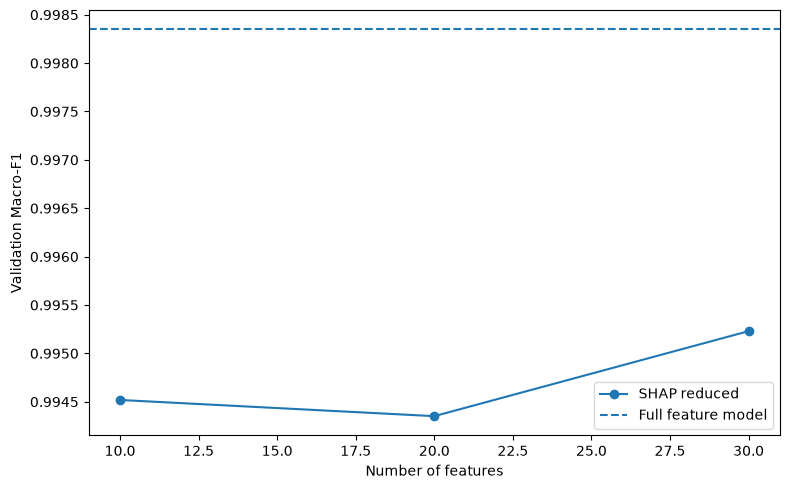

In [24]:
shap_reduction_validation_df = pd.DataFrame()
reduced_validation_models = {}
selected_reduced_features = []
SELECTED_SHAP_K = None

if BEST_TREE_PIPELINE is not None and SHAP_AVAILABLE and not shap_importance.empty:
    names = shap_importance.index.tolist()
    name_to_idx = {name: i for i, name in enumerate(names)}
    top_ks = sorted({min(int(k), len(names)) for k in TOP_K_FEATURES if int(k) > 0})
    top_ks = [k for k in top_ks if k < len(names)]
    if not top_ks and len(names) > 0:
        top_ks = [len(names)]

    pre = BEST_TREE_PIPELINE.named_steps["preprocessor"]
    selector = BEST_TREE_PIPELINE.named_steps["selector"]
    sampler_template = BEST_TREE_PIPELINE.named_steps["sampler"]
    model_template = BEST_TREE_PIPELINE.named_steps["model"]

    X_train_pre = pre.transform(X_train)
    X_val_pre = pre.transform(X_val)
    X_train_sel = selector.transform(X_train_pre) if selector != "passthrough" else X_train_pre
    X_val_sel = selector.transform(X_val_pre) if selector != "passthrough" else X_val_pre

    reduction_rows = []
    for k in top_ks:
        selected_names = names[:k]
        selected_idx = np.asarray([name_to_idx[n] for n in selected_names], dtype=int)
        X_tr_k = np.asarray(X_train_sel)[:, selected_idx]
        X_va_k = np.asarray(X_val_sel)[:, selected_idx]

        if sampler_template == "passthrough":
            X_fit, y_fit = X_tr_k, y_train
        else:
            sampler = clone(sampler_template)
            X_fit, y_fit = sampler.fit_resample(X_tr_k, y_train)

        model_k = clone(model_template).fit(X_fit, y_fit)
        pred = model_k.predict(X_va_k)
        prob = model_k.predict_proba(X_va_k)[:, 1]
        reduction_rows.append({
            "features_used": k,
            "feature_fraction": k / len(names),
            **calculate_metrics(y_val, pred, prob),
        })
        reduced_validation_models[k] = {
            "model": model_k, "indices": selected_idx, "features": selected_names
        }

    shap_reduction_validation_df = pd.DataFrame(reduction_rows).sort_values("features_used")
    display(shap_reduction_validation_df)
    save_table(shap_reduction_validation_df, "shap_feature_reduction_validation.csv")

    full_pred = BEST_TREE_PIPELINE.predict(X_val)
    full_prob = BEST_TREE_PIPELINE.predict_proba(X_val)[:, 1]
    full_val_metrics = calculate_metrics(y_val, full_pred, full_prob)
    eligible = shap_reduction_validation_df[
        shap_reduction_validation_df["f1_macro"] >= full_val_metrics["f1_macro"] - 0.01
    ]
    if len(eligible):
        SELECTED_SHAP_K = int(eligible.sort_values("features_used").iloc[0]["features_used"])
    else:
        SELECTED_SHAP_K = int(rank_validation_results(shap_reduction_validation_df).iloc[0]["features_used"])

    selected_reduced_features = reduced_validation_models[SELECTED_SHAP_K]["features"]
    print("Selected SHAP top-k:", SELECTED_SHAP_K)
    print(selected_reduced_features)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(shap_reduction_validation_df["features_used"], shap_reduction_validation_df["f1_macro"],
            marker="o", label="SHAP reduced")
    ax.axhline(full_val_metrics["f1_macro"], linestyle="--", label="Full feature model")
    ax.set_xlabel("Number of features")
    ax.set_ylabel("Validation Macro-F1")
    ax.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "shap_feature_reduction_validation.png", dpi=180)
    plt.show()
else:
    print("SHAP reduction skipped.")

## 26. Final test evaluation

Refit each tuned model on Train + Validation, then evaluate once on the untouched Test partition. Test metrics are for reporting only; do not return to the test set to pick methods or hyperparameters.

In [25]:
X_train_validation = pd.concat([X_train, X_val], axis=0)
y_train_validation = pd.concat([y_train, y_val], axis=0)

final_fitted_models = {}
test_prediction_store = {}
test_rows = []

for name in MODEL_NAMES:
    final_model = clone(hyperparameter_searches[name].best_estimator_)
    fit_start = time.perf_counter()
    final_model.fit(X_train_validation, y_train_validation)
    final_fit_seconds = time.perf_counter() - fit_start
    pred_start = time.perf_counter()
    pred = final_model.predict(X_test)
    prob = final_model.predict_proba(X_test)[:, 1]
    predict_seconds = time.perf_counter() - pred_start
    metrics = calculate_metrics(y_test, pred, prob)
    metrics.update({
        "final_fit_seconds": final_fit_seconds,
        "test_predict_seconds": predict_seconds,
        "predict_ms_per_row": predict_seconds * 1000 / max(1, len(X_test)),
    })
    test_rows.append({
        "model": name,
        "best_hyperparameters": repr(hyperparameter_searches[name].best_params_),
        **metrics,
    })
    final_fitted_models[name] = final_model
    test_prediction_store[name] = (pred, prob)

final_test_results_df = pd.DataFrame(test_rows).sort_values("f1_macro", ascending=False)
display(final_test_results_df)
save_table(final_test_results_df, "final_test_model_comparison.csv")

,model,best_hyperparameters,accuracy,precision_attack,recall_attack,f1_attack,f1_macro,f1_weighted,balanced_accuracy,roc_auc,...,mcc,false_positive_rate,false_negative_rate,TN,FP,FN,TP,final_fit_seconds,test_predict_seconds,predict_ms_per_row
2,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.998733,0.996505,0.997067,0.996786,0.997999,0.998733,0.998105,0.999904,...,0.995997,0.000858,0.002933,36104,31,26,8839,2.713251,0.152784,0.003395
1,Random Forest,"{'model__max_depth': None, 'model__min_samples...",0.998600,0.995720,0.997180,0.996449,0.997789,0.998600,0.998064,0.999893,...,0.995578,0.001052,0.002820,36097,38,25,8840,46.533173,0.319824,0.007107
0,Logistic Regression,{'model__C': 10.0},0.978733,0.912047,0.987253,0.948161,0.967392,0.979046,0.981948,0.994929,...,0.935971,0.023357,0.012747,35291,844,113,8752,41.715758,0.296239,0.006583


WindowsPath('E:/03 Education/Zagazig Material/Masters/First Year First Term/Machine Learning/Research Paper/ML for Intrusion Detection/reports/tables/final_test_model_comparison.csv')

## 27. Refit and test the selected SHAP-reduced tree model

The preprocessor and optional filter selector are refitted on Train + Validation only. The selected SHAP features are then used to fit the reduced model. The test partition is only transformed and predicted.

In [26]:
shap_reduced_test_record = None
shap_reduced_test_pred = None
shap_reduced_test_prob = None

if BEST_TREE_NAME is not None and SELECTED_SHAP_K is not None and selected_reduced_features:
    selected_pipeline = hyperparameter_searches[BEST_TREE_NAME].best_estimator_

    final_pre = clone(selected_pipeline.named_steps["preprocessor"]).fit(
        X_train_validation, y_train_validation
    )
    X_tv_pre = final_pre.transform(X_train_validation)
    X_test_pre = final_pre.transform(X_test)
    final_names = np.asarray(final_pre.get_feature_names_out(), dtype=object)

    selector_template = selected_pipeline.named_steps["selector"]
    if selector_template != "passthrough":
        final_selector = clone(selector_template).fit(X_tv_pre, y_train_validation)
        X_tv_sel = final_selector.transform(X_tv_pre)
        X_test_sel = final_selector.transform(X_test_pre)
        final_names = final_names[final_selector.get_support()]
    else:
        final_selector = "passthrough"
        X_tv_sel, X_test_sel = X_tv_pre, X_test_pre

    name_to_index = {name: i for i, name in enumerate(final_names)}
    missing_names = [n for n in selected_reduced_features if n not in name_to_index]
    if missing_names:
        raise ValueError(f"Feature names changed during refit: {missing_names}")
    selected_idx = np.asarray([name_to_index[n] for n in selected_reduced_features], dtype=int)

    X_tv_k = np.asarray(X_tv_sel)[:, selected_idx]
    X_test_k = np.asarray(X_test_sel)[:, selected_idx]

    sampler_template = selected_pipeline.named_steps["sampler"]
    if sampler_template == "passthrough":
        X_fit, y_fit = X_tv_k, y_train_validation
    else:
        final_sampler = clone(sampler_template)
        X_fit, y_fit = final_sampler.fit_resample(X_tv_k, y_train_validation)

    reduced_final_model = clone(selected_pipeline.named_steps["model"]).fit(X_fit, y_fit)
    shap_reduced_test_pred = reduced_final_model.predict(X_test_k)
    shap_reduced_test_prob = reduced_final_model.predict_proba(X_test_k)[:, 1]

    shap_reduced_test_record = {
        "model": f"{BEST_TREE_NAME} (SHAP top-{SELECTED_SHAP_K})",
        "feature_count": len(selected_reduced_features),
        **calculate_metrics(y_test, shap_reduced_test_pred, shap_reduced_test_prob),
    }
    display(pd.DataFrame([shap_reduced_test_record]))
    save_table(pd.DataFrame([shap_reduced_test_record]), "shap_reduced_model_test_metrics.csv")
    test_prediction_store[shap_reduced_test_record["model"]] = (
        shap_reduced_test_pred, shap_reduced_test_prob
    )
else:
    print("No SHAP-reduced final model was selected.")

,model,feature_count,accuracy,precision_attack,recall_attack,f1_attack,f1_macro,f1_weighted,balanced_accuracy,roc_auc,average_precision,mcc,false_positive_rate,false_negative_rate,TN,FP,FN,TP
0,XGBoost (SHAP top-10),10,0.997622,0.995474,0.992442,0.993956,0.996238,0.997621,0.995668,0.999801,0.999173,0.992478,0.001107,0.007558,36095,40,67,8798


## 28. Per-class reports, confusion matrices, ROC and Precision–Recall curves

The selected SHAP-reduced model is included in the plots when it was successfully constructed.

,precision,recall,f1-score,support,model,class
0,0.996808,0.976643,0.986623,36135.0,Logistic Regression,Benign
1,0.912047,0.987253,0.948161,8865.0,Logistic Regression,Attack
2,0.999308,0.998948,0.999128,36135.0,Random Forest,Benign
3,0.995720,0.997180,0.996449,8865.0,Random Forest,Attack
4,0.999280,0.999142,0.999211,36135.0,XGBoost,Benign
5,0.996505,0.997067,0.996786,8865.0,XGBoost,Attack
6,0.998147,0.998893,0.998520,36135.0,XGBoost (SHAP top-10),Benign
7,0.995474,0.992442,0.993956,8865.0,XGBoost (SHAP top-10),Attack


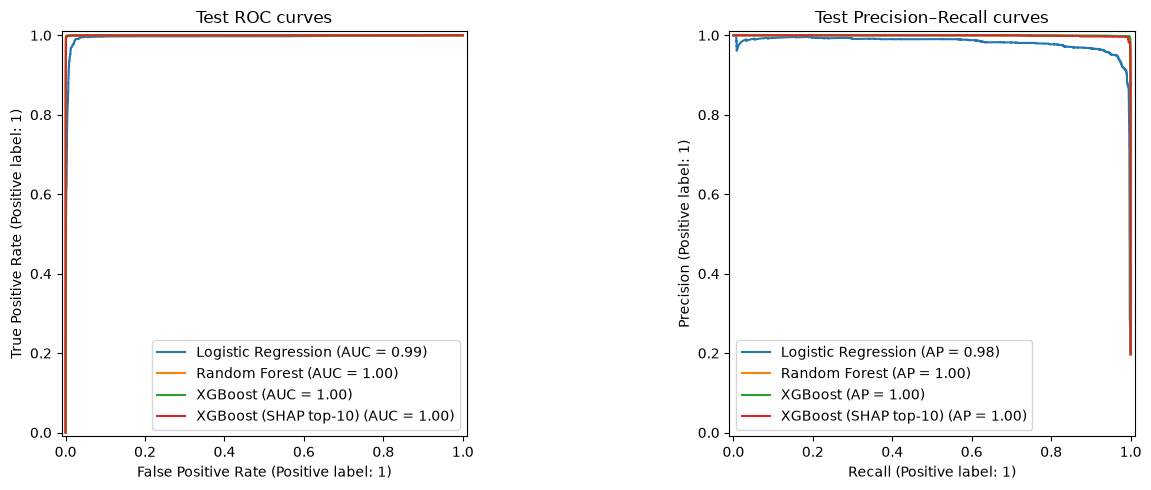

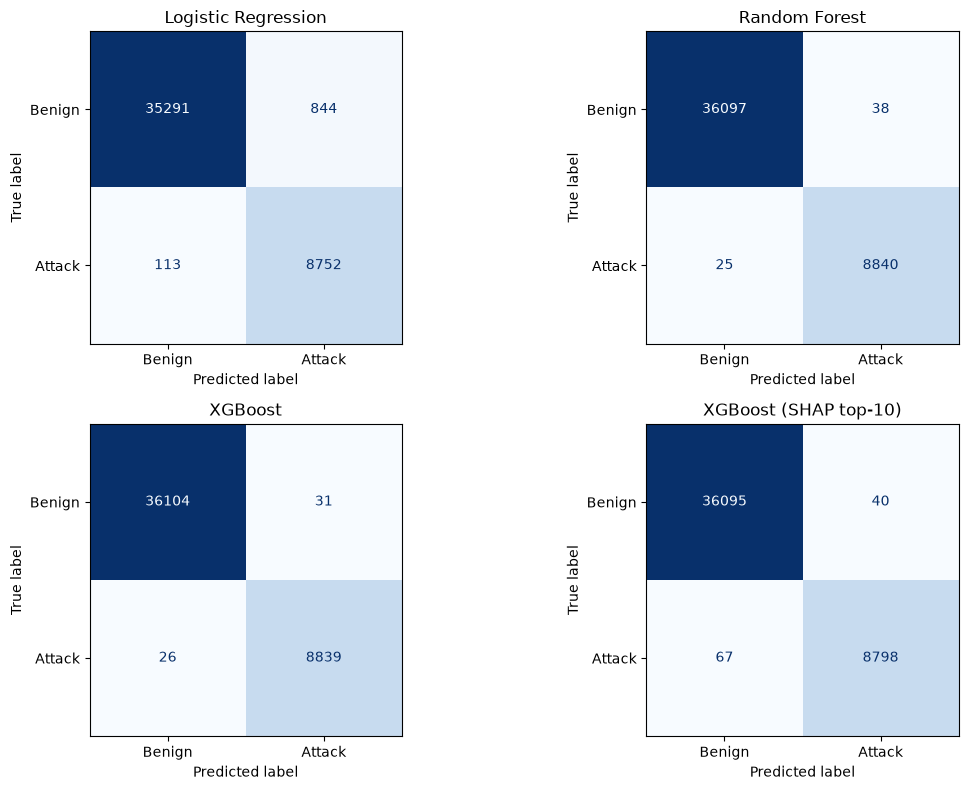

In [27]:
per_class_rows = []
for name, (pred, prob) in test_prediction_store.items():
    report = classification_report(
        y_test, pred, labels=[0, 1], target_names=["Benign", "Attack"],
        output_dict=True, zero_division=0
    )
    for class_name in ["Benign", "Attack"]:
        row = report[class_name].copy()
        row.update({"model": name, "class": class_name})
        per_class_rows.append(row)

per_class_df = pd.DataFrame(per_class_rows)
display(per_class_df)
save_table(per_class_df, "test_per_class_metrics.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, (pred, prob) in test_prediction_store.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=axes[1])
axes[0].set_title("Test ROC curves")
axes[1].set_title("Test Precision–Recall curves")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_roc_pr_curves.png", dpi=180)
plt.show()

n_models = len(test_prediction_store)
n_cols = 2
n_rows = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 4*n_rows))
axes = np.asarray(axes).reshape(-1)
for ax, (name, (pred, _)) in zip(axes, test_prediction_store.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1], display_labels=["Benign", "Attack"],
        values_format="d", cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name)
for ax in axes[n_models:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_confusion_matrices.png", dpi=180)
plt.show()

## 29. Experiment manifest and output inventory

The manifest records the data source, sample settings, split protocol, CV protocol, selected model parameters, SHAP subset, and package versions. This makes the results auditable and supports the Methodology/Results sections of the paper.

In [28]:
experiment_manifest = {
    "study": "CIC-IDS2017 binary NIDS: staged pipeline search, model tuning, SHAP analysis",
    "dataset_variant": "Original CIC-IDS2017 CSV files supplied by user",
    "raw_directory": str(RAW_DIR),
    "csv_files": [p.name for p in csv_files],
    "sampling_description": sampling_description,
    "max_rows_for_modeling": MAX_ROWS_FOR_MODELING,
    "search_max_rows": SEARCH_MAX_ROWS,
    "random_state": RANDOM_STATE,
    "split_strategy": SPLIT_STRATEGY,
    "cv_strategy": CV_STRATEGY,
    "cv_folds": CV_FOLDS,
    "target": "BENIGN=0; all other non-empty original labels=1",
    "models": MODEL_NAMES,
    "primary_metric": PRIMARY_SCORING,
    "method_catalogue_rows": len(METHOD_CATALOG),
    "best_validation_model": BEST_MODEL_NAME,
    "best_tree_model_for_shap": BEST_TREE_NAME,
    "best_imbalance_params": {m: repr(s.best_params_) for m, s in imbalance_searches.items()},
    "best_hyperparameters": {m: repr(s.best_params_) for m, s in hyperparameter_searches.items()},
    "combined_preprocessing_params": {m: repr(p) for m, p in combined_params_by_model.items()},
    "shap_selected_k": SELECTED_SHAP_K,
    "shap_selected_features": selected_reduced_features,
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "xgboost": xgb.__version__ if XGBOOST_AVAILABLE else None,
    "shap": shap.__version__ if SHAP_AVAILABLE else None,
}
manifest_path = TABLES_DIR / "experiment_manifest.json"
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(experiment_manifest, f, indent=2, default=str)

print("Tables:", TABLES_DIR)
print("Figures:", FIGURES_DIR)
print("Manifest:", manifest_path)

Tables: E:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\reports\tables
Figures: E:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\reports\figures
Manifest: E:\03 Education\Zagazig Material\Masters\First Year First Term\Machine Learning\Research Paper\ML for Intrusion Detection\reports\tables\experiment_manifest.json


## 30. Research interpretation and reproducibility checklist

### Dataset and quality
- [ ] Dataset version and all eight CSV inputs are identified.
- [ ] Per-file row counts and original attack-family counts are reported.
- [ ] Missing, infinite, duplicate, conflicting-vector, and outlier audits are reported.
- [ ] Cross-partition exact-vector overlap is reported.
- [ ] Any modeling sample is disclosed, including its sampling procedure.

### Experimental validity
- [ ] Split protocol matches the stated generalization question.
- [ ] All learned preprocessing is fitted inside CV training folds.
- [ ] Variance filtering / feature selection is fitted inside CV training folds.
- [ ] Resampling is applied only inside CV training folds.
- [ ] Pipeline and hyperparameter searches do not use the test set.
- [ ] Validation is used for finalist comparison.
- [ ] The final test partition is evaluated only after all choices are frozen.

### Results and limitations
- [ ] Report CV means and standard deviations, preferably per-fold results too.
- [ ] Report Attack Precision/Recall/F1, Macro-F1, PR-AUC, ROC-AUC, FPR/FNR and MCC.
- [ ] Explain false positives and false negatives.
- [ ] Explain whether individually good preprocessing choices interact when combined.
- [ ] Compare full-feature and SHAP-reduced models.
- [ ] Report training time and prediction latency where feasible.
- [ ] Acknowledge CIC-IDS2017's documented quality limitations.
- [ ] Do not claim zero-day detection, cross-network generalization, or real-time deployment.
- [ ] Acknowledge that repeated validation-based search can overfit the validation set; the untouched test set is the final check.

## 31. Methodological references and source provenance

### References used by the notebook
- Scikit-learn, *Common pitfalls and recommended practices*: https://scikit-learn.org/stable/common_pitfalls.html
- Scikit-learn, *Pipeline and composite estimators*: https://scikit-learn.org/stable/modules/compose.html
- Scikit-learn, *GridSearchCV*: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- Scikit-learn, *RandomizedSearchCV*: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html
- Imbalanced-learn, *Pipeline*: https://imbalanced-learn.org/stable/references/pipeline.html
- SHAP, *TreeExplainer*: https://shap.readthedocs.io/en/stable/generated/shap.TreeExplainer.html
- Canadian Institute for Cybersecurity, *CIC-IDS2017*: https://www.unb.ca/cic/datasets/ids-2017.html
- Engelen, Rimmer and Joosen (2021), *Troubleshooting an Intrusion Detection Dataset: The CICIDS2017 Case Study*.
- Liu et al. (2022), *Error Prevalence in NIDS Datasets: A Case Study on CIC-IDS-2017 and CSE-CIC-IDS-2018*.

### Supplied framework
The accompanying 36-page PDF is used as a method taxonomy and decision framework. Its generic pipeline options are not all valid search candidates for a low-cardinality Protocol feature or for this offline CIC-IDS2017 experiment. The notebook records which options are searched, conditional, deferred, visualization-only, or outside scope.